# Contrastive RL на JAX: семантические цели, завершение эпизода и PPO

Учебная реализация *Scaling Contrastive Reinforcement Learning to Open-Ended Environments* из предоставленной рукописи ICLR 2027. **Все сети, targets, автоматическое дифференцирование и обновления — JAX + Flax + Optax.** В комментариях показано, каким операциям PyTorch соответствует код.

Среды берутся из pip: **MiniGrid Empty**, **MiniGrid LavaCrossing** и **Craftax Classic**. Мы не реализуем их правила, карты или физику. Тонкие адаптеры только переводят API, наблюдения, предикаты целей и terminal flags в общий формат. MiniGrid исполняет Python/Gymnasium-код; его нельзя превратить в JAX-среду одной заменой библиотеки. Craftax исполняется нативно на JAX через `vmap`.

Здесь реализованы все три основных механизма §3: semantic + Rao–Blackwell targets, absorbing class + termination discount, совместное обучение CRL-teacher и PPO-student. **Сохранены пояснения, абляции, графики, инспектор, анимации и лаборатория параметров.** Код автономен: кроме pip-зависимостей notebook не импортирует локальные модули.

Это небольшой CPU-эксперимент, не воспроизведение миллиардного бюджета и таблиц статьи. Используется компактная MLP и 46 выбранных предикатов Craftax вместо точного набора 136/512 целей авторов. На таком бюджете дальние задачи Craftax могут вообще не освоиться. Проверка запуска и корректности формул не равна доказательству сходимости.

**Маршрут:** 1–3 — запуск и формулы; 4–5 — пакетные среды и terminal semantics; 6–9 — сети, rollout, CRL и PPO; 10–13 — эксперименты и интерпретация; 14–16 — интерактивность, масштабирование и самостоятельные опыты.

## 1. Зависимости, устройства и случайность

**Нужен Python 3.12+** для зафиксированных версий JAX/Flax. В новом окружении установите зависимости из `requirements-notebook.txt` или раскомментируйте `%pip` ниже; после установки перезапустите kernel. Эти версии проверяются в текущем прогоне. CPU-устройство подходит для демонстрации. Установка GPU-версии JAX — отдельный выбор под вашу CUDA; просто сменить название устройства недостаточно.

JAX использует **явные PRNG keys**: ключ делится перед каждым новым случайным событием. Повторное применение одного ключа даёт ту же случайность. В PyTorch обычно используются состояние генератора и `torch.manual_seed`; здесь ключи являются обычными аргументами pure functions. RNG среды и RNG политики разделены.

Первый запуск JIT включает компиляцию. Тайминги ниже синхронизируются, но включают первый compile при необходимости: это не честный бенчмарк алгоритмов по FLOPs. Повторный запуск ячеек с теми же формами обычно быстрее.

In [1]:
%matplotlib inline

# Если пакеты ещё не установлены, выполните один раз и перезапустите kernel:
# %pip install jax==0.11.2 jaxlib==0.11.2 flax==0.12.10 optax==0.2.8 craftax==1.6.1 minigrid==3.2.0 gymnasium==1.4.0 matplotlib ipywidgets pillow

import os
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")  # Рендер MiniGrid без окна SDL.
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import time
from dataclasses import dataclass, replace
from functools import lru_cache, partial
from importlib.metadata import version
from typing import Literal, NamedTuple

import numpy as np                       # Только Python-среда, I/O и графики.
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Markdown, display

import jax
import jax.numpy as jnp
from flax import linen as nn, struct
from flax.training.train_state import TrainState
import optax

import gymnasium as gym
import minigrid                          # Регистрирует официальные gym.make IDs.
from minigrid.wrappers import FullyObsWrapper
from minigrid.core.constants import OBJECT_TO_IDX
from craftax.craftax_env import make_craftax_env_from_name
from craftax.craftax_classic.constants import Action, BlockType, OBS_DIM
from craftax.craftax_classic.renderer import make_craftax_pixel_renderer

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for package in ("jax", "flax", "optax", "craftax", "minigrid", "gymnasium"):
    print(f"{package}: {version(package)}")
print("Устройства:", jax.devices())

jax: 0.11.2
flax: 0.12.10
optax: 0.2.8
craftax: 1.6.1
minigrid: 3.2.0
gymnasium: 1.4.0
Устройства: [CpuDevice(id=0)]


### Пульт эксперимента

`Config` — единственный основной набор настроек. Меняйте его через `replace(BASE, ...)`: это сохраняет исходный baseline. `num_envs × rollout_len` должно делиться на `batch_size`.

По умолчанию один seed для разумного CPU-времени; **статистических выводов по одному seed делать нельзя**. Для разброса задайте `SEEDS=(0,1,2,3,4)`: plotting-функции автоматически покажут mean ± std. При одном seed полоса неопределённости не рисуется. Горизонты и число раундов для Craftax сокращены отдельно, поэтому не сравнивайте абсолютный успех разных сред как единую сложность.

Все основные проверки выполняются автоматически. Дополнительные длинные опыты в `run_custom` и виджеты запускаются вручную. При изменении размерностей сети, `T`, batch или числа целей JAX может компилировать новые kernels; изменение discount обычно переиспользует скомпилированный код.

In [2]:
@dataclass(frozen=True)
class Config:
    # Размеры меняют формы массивов и могут потребовать новой JIT-компиляции.
    num_envs: int = 8
    rollout_len: int = 32
    rounds: int = 56
    episode_limit: int = 128
    hidden: int = 128
    embedding_dim: int = 32
    batch_size: int = 128
    critic_updates: int = 16
    replay_rollouts: int = 1              # 1 = только текущий rollout, как в статье.

    # Эти скаляры передаются в JIT динамически: абляции переиспользуют компиляцию.
    gamma: float = 0.97
    gamma_term: float = 0.90
    k_max: int = 32
    absorbing: bool = True
    rao_blackwell: bool = True
    critic_lr: float = 1e-3
    epsilon_start: float = 1.0
    epsilon_end: float = 0.15
    action_score: Literal["logit", "probability"] = "logit"

    ppo_lr: float = 3e-4
    ppo_epochs: int = 4
    gae_lambda: float = 0.95
    clip_epsilon: float = 0.2
    value_coef: float = 0.5
    entropy_coef: float = 0.01
    bc_beta: float = 0.2

    eval_every: int = 14
    eval_horizon: int = 64
    eval_goals: int = 8

    def validate(self):
        assert 0 < self.gamma < 1 and 0 <= self.gamma_term < 1
        assert self.k_max >= 1 and self.replay_rollouts >= 1
        assert self.num_envs * self.rollout_len % self.batch_size == 0
        assert self.action_score in ("logit", "probability")
        return self

BASE = Config().validate()
CRAFTAX_CONFIG = replace(BASE, rounds=28, eval_every=14, episode_limit=256)
SEEDS = (0,)   # Быстрый CPU-прогон. Для разброса: (0, 1, 2, 3, 4).
RUN_PPO = True
ENVIRONMENTS = {
    "empty": "MiniGrid-Empty-6x6-v0",
    "lava": "MiniGrid-LavaCrossingS9N1-v0",
    "craftax": "Craftax-Classic-Symbolic-v1",
}
# Дополнительная пакетная среда с ключом/дверью: MiniGrid-DoorKey-6x6-v0.
# Для долгого опыта: replace(BASE, rounds=500, num_envs=32, eval_every=50).

## 2. Из будущего состояния — в распределение семантических целей

Цель — предикат $P_g(s)\in\{0,1\}$. Один state может выполнять несколько целей, а одна цель — быть выполнена во многих states. Например: «есть древесина», «дерево слева», «вода ≥ 6». Обозначим $G^+(s)=\{g:P_g(s)=1\}$.

Метка будущего state вычисляется без reward:

$$\ell_g(s)=\begin{cases}\frac{\mathbf1[g\in G^+(s)]}{|G^+(s)|},&|G^+(s)|>0,\\0,&|G^+(s)|=0.\end{cases}$$

Это **категориальное распределение**, а не набор независимых вероятностей. Если одновременно выполнены три предиката, каждый получает $1/3$. Добавление похожего предиката меняет массу старых меток — это реальное свойство определения цели в статье, а не косметика.

При $k\ge1$, $P(k)=(1-\gamma)\gamma^{k-1}$, оценивается Eq. 5:

$$\rho^\pi_\gamma(g\mid s,a)=(1-\gamma)\sum_{k\ge1}\gamma^{k-1}\mathbb E_\pi[\ell_g(s_{t+k})\mid s_t=s,a_t=a].$$

Это **discounted goal occupancy**: какая доля геометрически выбранного будущего принадлежит цели. Это не вероятность «достигнуть хотя бы раз». И это не исходный $Q$ для бинарной награды $\mathbf1[P_g(s)]$, потому что появился делитель $|G^+(s)|$. Пропорциональность state-occupancy и $Q$ из §2 статьи нельзя без поправки переносить на нормированные semantic labels.

Ниже предикаты имеют одинаковый интерфейс: выбранный признак observation превышает порог. Описание цели — маска этого признака и сам порог. Поэтому goal encoder получает **содержание цели**, а не только её ID. Размерность описания фиксирована при увеличении числа целей в данной среде. Сеть сможет сделать forward для нового порога, но качество такого обобщения само собой не гарантируется.

In [3]:
@jax.jit
def goal_predicates(observations, feature_indices, thresholds):
    # PyTorch: observations[..., feature_indices] >= thresholds.
    values = jnp.take(observations, feature_indices, axis=-1)
    return (values >= thresholds).astype(jnp.float32)


@jax.jit
def semantic_labels(predicates):
    # PyTorch: p / p.sum(-1, keepdim=True).clamp(min=1).
    return predicates / jnp.maximum(predicates.sum(axis=-1, keepdims=True), 1.0)


@dataclass(frozen=True)
class GoalSpace:
    names: tuple[str, ...]
    feature_indices: jax.Array
    thresholds: jax.Array
    descriptors: jax.Array

    @classmethod
    def make(cls, names, indices, thresholds, obs_dim):
        indices = jnp.asarray(indices, jnp.int32)
        thresholds = jnp.asarray(thresholds, jnp.float32)
        # Описание цели = маска признака + порог. Параметры ψ не зависят от G.
        masks = jax.nn.one_hot(indices, obs_dim)
        descriptors = jnp.concatenate([masks, thresholds[:, None]], axis=-1)
        return cls(tuple(names), indices, thresholds, descriptors)

    @property
    def size(self):
        return len(self.names)

    def predicates(self, observations):
        return goal_predicates(observations, self.feature_indices, self.thresholds)

    def find(self, text):
        return next(i for i, name in enumerate(self.names) if text in name)


def craftax_goal_space(obs_dim, kind="semantic"):
    if kind == "observation":
        # Не отбрасываем структурно невозможные признаки: это не 1419 goals статьи.
        return GoalSpace.make([f"признак {i} активен" for i in range(obs_dim)],
                              range(obs_dim), [1e-5] * obs_dim, obs_dim)
    if kind != "semantic":
        raise ValueError("kind должен быть semantic или observation")
    map_dim = OBS_DIM[0] * OBS_DIM[1] * (len(BlockType) + 4)
    inventory = ("древесина", "камень", "уголь", "железо", "алмаз", "саженец",
                 "деревянная кирка", "каменная кирка", "железная кирка",
                 "деревянный меч", "каменный меч", "железный меч")
    names, indices, thresholds = [], [], []
    for i, name in enumerate(inventory):
        for count in ((1, 3) if i < 6 else (1,)):
            names.append(f"{name} ≥ {count}")
            indices.append(map_dim + i)
            thresholds.append((count - 0.01) / 10)  # Учитываем float16 native obs.
    directions = (("слева", 0, -1), ("справа", 0, 1),
                  ("сверху", -1, 0), ("снизу", 1, 0))
    blocks = (("дерево", BlockType.TREE), ("камень", BlockType.STONE),
              ("вода", BlockType.WATER), ("верстак", BlockType.CRAFTING_TABLE),
              ("печь", BlockType.FURNACE), ("лава", BlockType.LAVA))
    for direction, dy, dx in directions:
        y, x = OBS_DIM[0] // 2 + dy, OBS_DIM[1] // 2 + dx
        for name, block in blocks:
            names.append(f"{name} {direction}")
            indices.append((y * OBS_DIM[1] + x) * (len(BlockType) + 4) + block.value)
            thresholds.append(0.5)
    for i, name in enumerate(("здоровье", "еда", "вода", "энергия")):
        names.append(f"{name} ≥ 6")
        indices.append(map_dim + 12 + i)
        thresholds.append(0.599)
    return GoalSpace.make(names, indices, thresholds, obs_dim)

## 3. Почему нужен Rao–Blackwell и куда исчезает масса после смерти?

Обычный sampled target выбирает один offset $k$ и берёт $\ell(s_{t+k})$. Если будущее известно, можно заменить случайный offset его точным ожиданием внутри доступного окна (Eq. 6):

$$\bar y_t(g)=\sum_{k=1}^{K_t}\underbrace{\frac{(1-\gamma)\gamma^{k-1}}{1-\gamma^{K_t}}}_{w_k}\ell_g(s_{t+k}).$$

Здесь $K_t$ ограничен rollout-окном, границей эпизода и `k_max`. RB убирает дисперсию offset при фиксированной траектории, а не весь шум среды и SGD. Семантическое усреднение по целям уже вычислено точно и при `rao_blackwell=False`: эта абляция меняет только offset.

Если действие оборвало будущее, перенормировка над оставшимися states условна на выживание. Fatal anchor вообще не получает обычной положительной метки. В статье добавляют класс $\varnothing$ с **фиксированным logit 0** (Eq. 7):

$$Z=1+\sum_g e^{f(s,a,g)},\quad p_g=e^{f_g}/Z,\quad p_\varnothing=1/Z.$$

При наблюдаемом поглощении (Eq. 8):

$$y_t(g)=(1-\gamma_{term}^{\Delta_t})\bar y_t(g),\qquad y_t(\varnothing)=1-\sum_g y_t(g).$$

- **Fatal transition:** следующая observation не считается живым будущим; $\Delta=0$ для последнего действия, target целиком $\varnothing$.
- **Успешный terminal в MiniGrid:** последняя observation действительно выполняет цель и учитывается; для этого действия $\Delta=1$. Это явная адаптация к episodic MiniGrid: стандартная среда статьи не заканчивается после достижения команды.
- **Time-limit:** это `truncated`, не поглощение; final observation сохраняется, штраф за ненаблюдаемое будущее не добавляется.
- **Конец rollout:** тоже не смерть. Если terminal не виден в окне, termination-множитель равен 1.

Пример смерти: `s0 → s1 → s2 → смерть` даёт $\Delta=[2,1,0]$. При `gamma_term=gamma` и полном будущем $K_t=\Delta_t$ нормировка сокращается и восстанавливается геометрическая масса до поглощения. Если `k_max < Δ` или конец не виден, конечное окно сохраняет смещение; RB не устраняет его. `gamma_term < gamma` — осознанное изменение дальности штрафа, не точная исходная occupancy.

В коде сначала строятся `[B,T,T]` маски допустимых будущих, затем одно `einsum` усредняет их метки. Это квадратично по длине окна, поэтому не ставьте огромный `rollout_len` без оценки памяти. Episode ID не даёт соседним эпизодам одного batch-слота обменяться будущими.

In [4]:
@struct.dataclass
class TargetOptions:
    gamma: float
    gamma_term: float
    k_max: int
    absorbing: bool
    rao_blackwell: bool

    @classmethod
    def from_config(cls, config):
        return cls(config.gamma, config.gamma_term, config.k_max,
                   config.absorbing, config.rao_blackwell)


@struct.dataclass
class Targets:
    distribution: jax.Array              # [T, B, G+1]; последний класс всегда ∅.
    valid: jax.Array                     # [T, B]; baseline исключает fatal anchors.
    future_count: jax.Array              # [T, B]


@jax.jit
def build_targets(next_predicates, terminated, truncated, fatal, key, options):
    """Векторизованные Eq. 4, 6–8. Никаких переходов через reset."""
    time_steps = next_predicates.shape[0]
    labels = semantic_labels(next_predicates) * (~fatal)[..., None]
    done = terminated | truncated
    # Episode ID относится к anchor ДО действия, а не к final obs ПОСЛЕ него.
    episode_id = jnp.cumsum(done, axis=0) - done.astype(jnp.int32)
    episode_id = episode_id.T                           # [B, T]
    same_episode = episode_id[:, :, None] == episode_id[:, None, :]
    offset = jnp.arange(time_steps)[None, :] - jnp.arange(time_steps)[:, None]
    forward = offset >= 0
    available = same_episode & forward & (offset < options.k_max) & (~fatal.T[:, None, :])
    unnormalized = jnp.where(available, options.gamma ** jnp.maximum(offset, 0), 0.0)
    total = unnormalized.sum(-1, keepdims=True)
    weights = unnormalized / jnp.maximum(total, 1e-12)
    labels_bt = labels.transpose(1, 0, 2)
    averaged = jnp.einsum("bij,bjg->big", weights, labels_bt)
    # PyTorch: batched matmul/bmm(weights, labels). Нормировка остаётся differentiable,
    # но сами labels ниже stop_gradient: среды не обучаются градиентом critic loss.
    fallback = jax.nn.one_hot(jnp.zeros(weights.shape[:2], jnp.int32), time_steps)
    sampling_weights = jnp.where(total > 0, weights, fallback)
    sampled_offset = jax.random.categorical(key, jnp.where(sampling_weights > 0, jnp.log(sampling_weights), -jnp.inf), axis=-1)
    sampled = jax.vmap(lambda table, rows: table[rows])(labels_bt, sampled_offset)
    sampled = sampled * (total > 0)
    target = jnp.where(options.rao_blackwell, averaged, sampled)

    terminal_future = same_episode & forward & terminated.T[:, None, :]
    # fatal transition: Δ=0; успешная terminal observation: Δ=1 для последнего action.
    terminal_delta = offset + (~fatal.T[:, None, :]).astype(jnp.int32)
    delta = jnp.min(jnp.where(terminal_future, terminal_delta, time_steps + 1), axis=-1)
    observed_termination = terminal_future.any(-1)
    retained_mass = jnp.where(observed_termination, 1.0 - options.gamma_term ** delta, 1.0)
    target = target * jnp.where(options.absorbing, retained_mass[..., None], 1.0)
    mass = target.sum(-1, keepdims=True)
    # Без ∅ categorical CE условна на существование метки; нулевые anchors пропускаются.
    real_target = jnp.where(options.absorbing, target, target / jnp.maximum(mass, 1e-12))
    residual = jnp.where(options.absorbing, jnp.clip(1.0 - mass, 0.0, 1.0), 0.0)
    distribution = jnp.concatenate([real_target, residual], axis=-1).transpose(1, 0, 2)
    valid = jnp.where(options.absorbing, True, mass[..., 0] > 0).T
    return Targets(jax.lax.stop_gradient(distribution), valid, available.sum(-1).T)

### Разобрать формулу на числах

Левая панель показывает отсутствие метки у fatal action; средняя исправляет последний action; правая переносит часть массы раньше. Проверки ниже также убеждаются, что reset не создаёт ложного будущего и что успешное завершение отличается от смерти. Error bars у sampled target — стандартное отклонение **отдельной случайной метки**, не доверительный интервал результата обучения.

В baseline без $\varnothing$ нулевые anchors пропускаются, а ненулевые target-векторы нормируются по семантической массе. Таким образом baseline условен и на доступное будущее, и на существование метки. Это существенно для Craftax: некоторые observations могут не выполнять ни одного из выбранных предикатов. В варианте с $\varnothing$ отсутствующая семантическая масса корректно остаётся в residual class.

Targets: нормировка, индексы, fatal/success/time-limit, reset и пустые предикаты — OK.


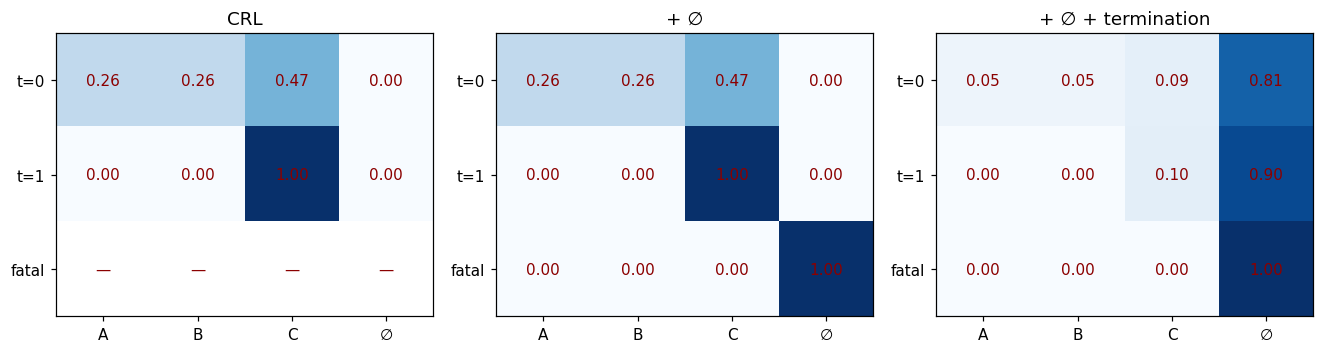

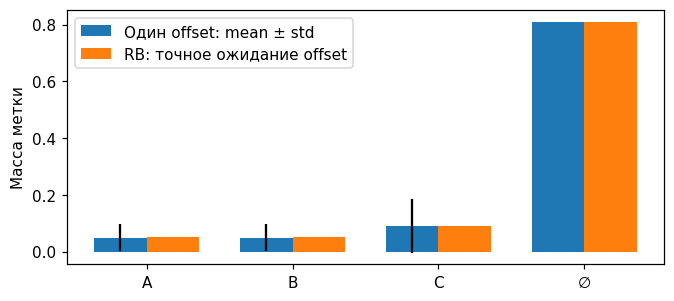

In [5]:
def target_example(absorbing=True, gamma_term=0.9, rb=True, key=None):
    # s0 -> s1(A,B) -> s2(C) -> смерть; затем НОВЫЙ эпизод с целью A.
    predicates = jnp.array([[1., 1., 0.], [0., 0., 1.], [0., 0., 0.], [1., 0., 0.]])[:, None]
    term = jnp.array([False, False, True, False])[:, None]
    fatal = term
    options = TargetOptions(0.9, gamma_term, 32, absorbing, rb)
    return build_targets(predicates, term, jnp.zeros_like(term), fatal,
                         jax.random.PRNGKey(0) if key is None else key, options)


def verify_targets():
    y = np.asarray(target_example().distribution[:, 0])
    np.testing.assert_allclose(y.sum(-1), 1, atol=1e-6)
    np.testing.assert_allclose(y[0], [0.05, 0.05, 0.09, 0.81], atol=1e-6)
    np.testing.assert_allclose(y[2], [0, 0, 0, 1], atol=1e-6)
    np.testing.assert_allclose(y[3], [1, 0, 0, 0], atol=1e-6)  # Не пересекли reset.
    assert np.asarray(target_example(False).valid[:, 0]).tolist() == [True, True, False, True]
    # Настоящий success terminal сохраняет immediate goal; tail — поглощение.
    p = jnp.ones((1, 1, 1)); yes = jnp.ones((1, 1), bool); no = ~yes
    options = TargetOptions(.9, .9, 8, True, True)
    success = build_targets(p, yes, no, no, jax.random.PRNGKey(1), options)
    timeout = build_targets(p, no, yes, no, jax.random.PRNGKey(1), options)
    np.testing.assert_allclose(success.distribution, [[[.1, .9]]], atol=1e-6)
    np.testing.assert_allclose(timeout.distribution, [[[1., 0.]]], atol=1e-6)
    empty = build_targets(p * 0, no, no, no, jax.random.PRNGKey(1), options)
    np.testing.assert_allclose(empty.distribution, [[[0., 1.]]], atol=1e-6)
    print("Targets: нормировка, индексы, fatal/success/time-limit, reset и пустые предикаты — OK.")


verify_targets()
fig, axes = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
for ax, (name, absorbing, discount) in zip(axes, [
        ("CRL", False, 0.), ("+ ∅", True, 0.), ("+ ∅ + termination", True, .9)]):
    result = target_example(absorbing, discount)
    y = np.asarray(result.distribution[:3, 0]).copy()
    valid = np.asarray(result.valid[:3, 0])
    y[~valid] = np.nan
    ax.imshow(y, vmin=0, vmax=1, cmap="Blues")
    ax.set(xticks=range(4), xticklabels=["A", "B", "C", "∅"],
           yticks=range(3), yticklabels=["t=0", "t=1", "fatal"], title=name)
    for t in range(3):
        for g in range(4):
            ax.text(g, t, f"{y[t,g]:.2f}" if valid[t] else "—", ha="center", va="center", color="darkred")
plt.show()

keys = jax.random.split(jax.random.PRNGKey(11), 4000)
sampled_targets = jax.vmap(lambda key: target_example(rb=False, key=key).distribution[0, 0])(keys)
rb_target = target_example().distribution[0, 0]
np.testing.assert_allclose(np.asarray(sampled_targets.mean(0)), np.asarray(rb_target), atol=.006)
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(4)
ax.bar(x-.18, np.asarray(sampled_targets.mean(0)), .36,
       yerr=np.asarray(sampled_targets.std(0)), label="Один offset: mean ± std")
ax.bar(x+.18, np.asarray(rb_target), .36, label="RB: точное ожидание offset")
ax.set(xticks=x, xticklabels=["A", "B", "C", "∅"], ylabel="Масса метки")
ax.legend(); plt.show()

## 4. MiniGrid из pip: наблюдения, цели и terminal observations

`gym.make` создаёт настоящие зарегистрированные среды, `FullyObsWrapper` включает глобальное наблюдение. Мы добавляем наблюдаемые в полном state положение, направление, наличие ключа и флаг открытой двери в числовую векторную кодировку. Это делает задачу проще стандартного частично наблюдаемого MiniGrid; результаты к default egocentric setting не переносятся.

MiniGrid имеет 7 действий, включая повороты, движение вперёд, pickup/drop/toggle/done. Мы не заменяем их четырьмя самописными перемещениями. Предикаты — клетки, две области, зелёная цель, а в DoorKey — также ключ/дверь. Шаблон целей берётся с native-карты; lava/walls исключены из пространственных целей.

Для чистого сравнения MiniGrid сбрасывается на один `layout_seed=0`: обучение и оценка здесь проверяют управление на фиксированной карте. Craftax ниже генерирует новые карты из отдельного RNG. Обобщение MiniGrid на новые layouts в этом notebook не заявляется.

`Step.observation` — состояние после действия **до reset**, а `env.observation` — начало следующего действия, уже после reset при необходимости. В PPO первое нужно для time-limit bootstrap, второе — для следующего rollout. В CRL первое нужно для правильных будущих меток. Их подмена — распространённая ошибка.

In [6]:
@struct.dataclass
class Step:
    observation: jax.Array               # ФИНАЛЬНАЯ obs перехода, до reset.
    predicates: jax.Array
    terminated: jax.Array
    truncated: jax.Array
    fatal: jax.Array
    native_reward: jax.Array
    health: jax.Array
    position: jax.Array


class MiniGridBatch:
    """Тонкий адаптер pip MiniGrid; правила движения/мира задаёт сам пакет."""

    def __init__(self, env_id, batch_size, seed, episode_limit, layout_seed=0):
        self.env_id, self.batch_size = env_id, batch_size
        self.layout_seed = layout_seed
        self.envs = [FullyObsWrapper(gym.make(env_id, render_mode="rgb_array",
                                            max_steps=episode_limit))
                     for _ in range(batch_size)]
        # Один layout на train/eval: это контрольная задача, не тест новых карт.
        observations = [e.reset(seed=layout_seed)[0] for e in self.envs]
        base = self.envs[0].unwrapped
        self.width, self.height = base.width, base.height
        self.position_offset = self.width * self.height * 3
        self.flag_offset = self.position_offset + self.width * self.height + 4
        features = np.stack([self.encode(e, o) for e, o in zip(self.envs, observations)])
        self.observation = jnp.asarray(features)
        self.obs_dim, self.n_actions = features.shape[-1], base.action_space.n
        self.action_names = ("влево ↶", "вправо ↷", "вперёд", "поднять", "бросить", "открыть", "done")
        self.goals = self.make_goal_space(base)
        self.record_first = False
        self.last_frame = None

    def encode(self, env, observation):
        base = env.unwrapped
        image = observation["image"].astype(np.float32) / np.array([10, 5, 2], np.float32)
        x, y = base.agent_pos
        position = np.eye(base.width * base.height, dtype=np.float32)[x * base.height + y]
        direction = np.eye(4, dtype=np.float32)[base.agent_dir]
        carrying_key = base.carrying is not None and base.carrying.type == "key"
        raw = base.grid.encode()  # Не теряем дверь под агентом в FullyObs image.
        open_door = np.any((raw[..., 0] == OBJECT_TO_IDX["door"]) & (raw[..., 2] == 0))
        on_goal = raw[x, y, 0] == OBJECT_TO_IDX["goal"]
        flags = np.array([carrying_key, open_door, on_goal,
                          x <= base.width // 2, x >= base.width // 2], np.float32)
        return np.concatenate([image.ravel(), position, direction, flags])

    def make_goal_space(self, base):
        raw = base.grid.encode()[..., 0]
        names, indices = [], []
        excluded = (OBJECT_TO_IDX["wall"], OBJECT_TO_IDX["lava"], OBJECT_TO_IDX["unseen"])
        for x in range(base.width):
            for y in range(base.height):
                if raw[x, y] not in excluded:
                    names.append(f"клетка ({x},{y})")
                    indices.append(self.position_offset + x * base.height + y)
        extras = [("левая область", 3), ("правая область", 4), ("зелёная цель", 2)]
        if (raw == OBJECT_TO_IDX["key"]).any(): extras.append(("есть ключ", 0))
        if (raw == OBJECT_TO_IDX["door"]).any(): extras.append(("дверь открыта", 1))
        for name, offset in extras:
            names.append(name); indices.append(self.flag_offset + offset)
        return GoalSpace.make(names, indices, [0.5] * len(names), self.obs_dim)

    def step(self, actions):
        features, rewards, terminated, truncated, fatal, positions = [], [], [], [], [], []
        next_current = []
        for i, (env, action) in enumerate(zip(self.envs, np.asarray(actions))):
            observation, reward, term, trunc, _ = env.step(int(action))
            base = env.unwrapped
            x, y = base.agent_pos
            died = bool(term and base.grid.get(x, y).type == "lava")
            features.append(self.encode(env, observation))
            positions.append((x, y)); rewards.append(reward)
            terminated.append(term); truncated.append(trunc and not term); fatal.append(died)
            if self.record_first and i == 0:
                self.last_frame = base.get_frame(highlight=False, tile_size=24)
            if term or trunc:
                observation, _ = env.reset(seed=self.layout_seed)
            next_current.append(self.encode(env, observation))
        final_obs = jnp.asarray(np.stack(features))
        self.observation = jnp.asarray(np.stack(next_current))
        return Step(final_obs, self.goals.predicates(final_obs),
                    jnp.asarray(terminated), jnp.asarray(truncated), jnp.asarray(fatal),
                    jnp.asarray(rewards), jnp.full(self.batch_size, jnp.nan), jnp.asarray(positions))

    def frame(self):
        return self.envs[0].unwrapped.get_frame(highlight=False, tile_size=24)

    def close(self):
        for env in self.envs: env.close()

## 5. Craftax Classic из pip: native JAX и 46 семантических целей

Используется `Craftax-Classic-Symbolic-v1`, стандартная карта $64\times64$, все 17 native actions, стандартные мобы, ресурсы и крафт. Ограничение длительности передаётся через предусмотренный `EnvParams.max_timesteps`. Физика, здоровье, атаки, ресурсы и достижимость не переписываются.

Native symbolic observation имеет локальную карту $7\times9$, инвентарь и intrinsic features. Она остаётся частично наблюдаемой: MLP без памяти не видит весь мир. Для точного reproduction понадобились бы архитектура, scheduler, goals и масштаб обучения авторов.

Выбранные 46 целей: 18 порогов количества предметов/наличия инструментов, 24 сочетания «тип блока рядом × направление», 4 порога intrinsic stats. Все предикаты читаются из той же observation, которая доступна сети; глобальные скрытые координаты и future achievements не идут в critic inputs. Позиции используются только для диагностики. Это компактный учебный goal set, не точный semantic goal set статьи.

`auto_reset=False` сохраняет final observation. Адаптер отдельно определяет смерть по native health/lava и отделяет её от time-limit. `vmap` выполняет несколько экземпляров пакетной среды, а не придумывает другую динамику. Reset вызывается только при native done; живые batch-слоты продолжают эпизод.

In [7]:
@lru_cache(maxsize=16)
def craftax_kernels(batch_size, episode_limit):
    # auto_reset=False необходим, чтобы не спутать final obs и новый эпизод.
    env = make_craftax_env_from_name("Craftax-Classic-Symbolic-v1", auto_reset=False)
    params = env.default_params.replace(max_timesteps=episode_limit)
    reset = jax.jit(jax.vmap(lambda key: env.reset(key, params)))
    step = jax.jit(jax.vmap(lambda key, state, action: env.step(key, state, action, params)))
    return env, reset, step


@lru_cache(maxsize=1)
def craftax_renderer():
    return jax.jit(make_craftax_pixel_renderer(16))


class CraftaxBatch:
    """Native JAX Craftax. Здесь нет реализации правил survival/crafting."""

    def __init__(self, batch_size, seed, episode_limit, goal_kind="semantic"):
        self.batch_size = batch_size
        self.env, self.reset_fn, self.step_fn = craftax_kernels(batch_size, episode_limit)
        self.key = jax.random.PRNGKey(seed)
        self.observation, self.state = self.reset_fn(self.split_keys())
        self.observation = self.observation.astype(jnp.float32)
        self.obs_dim, self.n_actions = self.observation.shape[-1], self.env.num_actions
        self.goals = craftax_goal_space(self.obs_dim, goal_kind)
        self.action_names = tuple(action.name for action in Action)
        self.record_first = False
        self.last_frame = None

    def split_keys(self):
        self.key, key = jax.random.split(self.key)
        return jax.random.split(key, self.batch_size)

    def step(self, actions):
        obs, state, reward, done, _ = self.step_fn(self.split_keys(), self.state, actions)
        # done Craftax объединяет смерть и time-limit; разделяем по native state.
        positions = state.player_position
        tile = jax.vmap(lambda m, p: m[p[0], p[1]])(state.map, positions)
        fatal = (state.player_health <= 0) | (tile == BlockType.LAVA.value)
        terminated = done & fatal
        truncated = done & ~fatal
        obs = obs.astype(jnp.float32)
        result = Step(obs, self.goals.predicates(obs), terminated, truncated, fatal,
                      reward, state.player_health.astype(jnp.float32), positions[:, ::-1])
        if self.record_first:
            first = jax.tree.map(lambda array: array[0], state)
            self.last_frame = np.asarray(craftax_renderer()(first)).astype(np.uint8)
        # Reset исполняется только после done; raw terminal obs уже сохранена в result.
        if bool(jnp.any(done)):
            reset_obs, reset_state = self.reset_fn(self.split_keys())
            state = jax.tree.map(
                lambda fresh, old: jnp.where(done.reshape((-1,) + (1,) * (old.ndim - 1)), fresh, old),
                reset_state, state)
            obs = jnp.where(done[:, None], reset_obs, obs)
        self.state, self.observation = state, obs.astype(jnp.float32)
        return result

    def frame(self):
        first = jax.tree.map(lambda array: array[0], self.state)
        return np.asarray(craftax_renderer()(first)).astype(np.uint8)

    def close(self):
        pass  # В functional Craftax нет окон, сокетов или фоновых процессов.


def make_environment(name, config, seed=0, goal_kind="semantic"):
    if name == "craftax":
        return CraftaxBatch(config.num_envs, seed, config.episode_limit, goal_kind)
    env_id = ENVIRONMENTS.get(name, name)
    return MiniGridBatch(env_id, config.num_envs, seed, config.episode_limit)

empty | native: minigrid.envs.empty | активные цели в первом наблюдении: 2


lava | native: minigrid.envs.crossing | активные цели в первом наблюдении: 2


Loading Craftax-Classic textures from cache.


Textures successfully loaded from cache.


craftax | native: craftax.craftax_classic.envs.craftax_symbolic_env | активные цели в первом наблюдении: 4


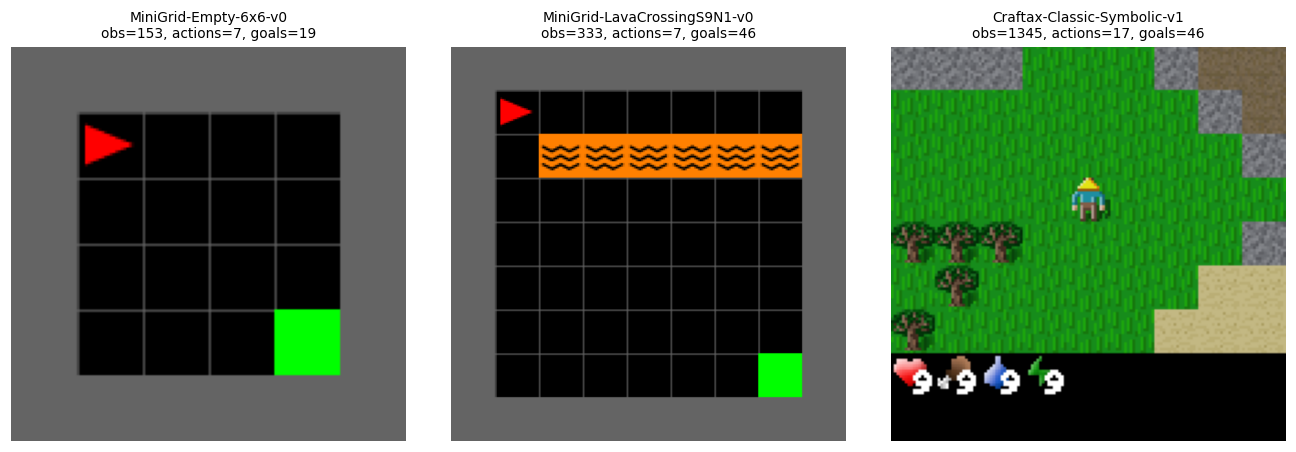

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, name in zip(axes, ENVIRONMENTS):
    config = CRAFTAX_CONFIG if name == "craftax" else BASE
    env = make_environment(name, config)
    ax.imshow(env.frame()); ax.axis("off")
    ax.set_title(f"{ENVIRONMENTS[name]}\nobs={env.obs_dim}, actions={env.n_actions}, goals={env.goals.size}", fontsize=9)
    print(name, "| native:", type(env.env).__module__ if name=="craftax" else type(env.envs[0].unwrapped).__module__,
          "| активные цели в первом наблюдении:", int(env.goals.predicates(env.observation)[0].sum()))
    env.close()
plt.show()

## 6. Нейросетевой критик и политика: функциональный JAX вместо PyTorch

$$f_\phi(s,a,g)=\phi(s,a)^\top\psi(g),\qquad L_C=-\sum_g y_g\log p_g.$$

State encoder выдаёт векторы всех действий `[B,A,d]`, goal encoder — `[G,d]`; `einsum` получает `[B,A,G]`. Никаких обучаемых state-ID таблиц теперь нет. Goal encoder обрабатывает описания предикатов; при добавлении целей его параметры не растут, хотя descriptors и logits занимают больше памяти.

Фиксированный нулевой logit класса $\varnothing$ не добавляет обучаемых параметров. При $y_\varnothing=1$ loss равен $\log(1+\sum_g e^{f_g})$, его derivative по каждому $f_g$ положительна, и gradient descent снижает все goal logits смертельного action.

Для discrete actions статья выбирает **argmax $f$**. При absorbing class оптимальный logit имеет смысл $\log(p_g/p_\varnothing)$, поэтому ranking по нему может отличаться от ranking по $p_g$. Высокая безопасность иногда превращается в предпочтение стоять на месте. `action_score="probability"` — доступная диагностическая альтернатива, но это уже другой способ управления.

В JAX `params` — явный PyTree, Flax `init/apply` не хранит скрытое изменяемое состояние обучения. `TrainState` объединяет параметры, optimizer state и шаг. Его новое значение нужно присвоить; вызов `apply_gradients` не меняет старый объект. Ниже Optax RAdam используется для CRL, Adam — для PPO, как в экспериментальной схеме статьи. Компактная MLP заменяет большую convolutional backbone для учебного CPU-бюджета.

In [9]:
class MLP(nn.Module):
    widths: tuple[int, ...]

    @nn.compact
    def __call__(self, x):
        for width in self.widths:
            x = nn.gelu(nn.Dense(width)(x))
        return x


class ContrastiveCritic(nn.Module):
    n_actions: int
    hidden: int
    embedding_dim: int

    @nn.compact
    def __call__(self, observations, goal_descriptors):
        state_hidden = MLP((self.hidden, self.hidden), name="state_encoder")(observations)
        phi = nn.Dense(self.n_actions * self.embedding_dim, name="state_actions")(state_hidden)
        phi = phi.reshape((*observations.shape[:-1], self.n_actions, self.embedding_dim))
        goal_hidden = MLP((self.hidden,), name="goal_encoder")(goal_descriptors)
        psi = nn.Dense(self.embedding_dim, name="goal_projection")(goal_hidden)
        # PyTorch: torch.einsum('...ad,gd->...ag', phi, psi).
        return jnp.einsum("...ad,gd->...ag", phi, psi)


class ActorCritic(nn.Module):
    n_actions: int
    hidden: int

    @nn.compact
    def __call__(self, observations, commanded_descriptors):
        inputs = jnp.concatenate([observations, commanded_descriptors], axis=-1)
        hidden = MLP((self.hidden, self.hidden))(inputs)
        logits = nn.Dense(self.n_actions, kernel_init=nn.initializers.orthogonal(.01), name="policy")(hidden)
        value = nn.Dense(1, name="value")(hidden)[..., 0]
        return logits, value


@jax.jit
def class_log_probs(logits, absorbing):
    log_normalizer = jax.scipy.special.logsumexp(logits, axis=-1, keepdims=True)
    # Фиксированный logit ∅ = 0. PyTorch: cat([logits, zeros], -1).log_softmax(-1).
    log_normalizer = jnp.where(absorbing, jnp.logaddexp(0., log_normalizer), log_normalizer)
    absorbing_logp = jnp.where(absorbing, -log_normalizer, -1e30)
    return jnp.concatenate([logits - log_normalizer, absorbing_logp], axis=-1)


@jax.jit
def critic_action(state, observation, descriptors, goals, key, epsilon, probability_score, absorbing):
    logits = state.apply_fn({"params": state.params}, observation, descriptors)
    probabilities = jnp.exp(class_log_probs(logits, absorbing))[..., :-1]
    scores = jnp.where(probability_score, probabilities, logits)
    selected = jnp.take_along_axis(scores, goals[:, None, None], axis=-1)[..., 0]
    greedy = selected.argmax(-1)
    explore_key, action_key = jax.random.split(key)
    random_actions = jax.random.randint(action_key, greedy.shape, 0, logits.shape[-2])
    return jnp.where(jax.random.uniform(explore_key, greedy.shape) < epsilon, random_actions, greedy)


@jax.jit
def actor_action(state, observation, descriptors, goals, key, greedy=False):
    logits, values = state.apply_fn({"params": state.params}, observation, descriptors[goals])
    actions = jnp.where(greedy, logits.argmax(-1), jax.random.categorical(key, logits))
    logp = jnp.take_along_axis(jax.nn.log_softmax(logits), actions[:, None], axis=-1)[:, 0]
    # PyTorch: Categorical(logits=...).sample(), .log_prob(), network.value.
    return actions, logp, values


@jax.jit
def actor_value(state, observations, descriptors, goals):
    return state.apply_fn({"params": state.params}, observations, descriptors[goals])[1]


@lru_cache(maxsize=16)
def learner_components(n_actions, hidden, embedding_dim, critic_lr, ppo_lr):
    # TrainState хранит apply_fn/tx как static metadata. Общие объекты = меньше retracing.
    critic = ContrastiveCritic(n_actions, hidden, embedding_dim)
    actor = ActorCritic(n_actions, hidden)
    c_tx = optax.chain(optax.clip_by_global_norm(1.), optax.radam(critic_lr))
    p_tx = optax.chain(optax.clip_by_global_norm(.5), optax.adam(ppo_lr))
    return critic, actor, c_tx, p_tx


def initialize_learners(env, config, seed):
    key_c, key_p = jax.random.split(jax.random.PRNGKey(seed))
    critic, actor, c_tx, p_tx = learner_components(env.n_actions, config.hidden, config.embedding_dim,
                                                   config.critic_lr, config.ppo_lr)
    c_params = critic.init(key_c, env.observation, env.goals.descriptors)["params"]
    p_params = actor.init(key_p, env.observation, env.goals.descriptors[jnp.zeros(env.batch_size, jnp.int32)])["params"]
    # PyTorch: optimizer хранится отдельно. TrainState явно хранит params + opt_state.
    return (TrainState.create(apply_fn=critic.apply, params=c_params, tx=c_tx),
            TrainState.create(apply_fn=actor.apply, params=p_params, tx=p_tx))

## 7. Rollout: одна траектория обучает все цели

Команды выбираются из ранее наблюдавшихся целей. После достижения команды или native done берётся новая. Если команда уже выполняется, возможны тривиальные повторные успехи — следите за разбивкой по целям, а не только за средним. На старте curriculum ещё не знает редких предметов: их должно открыть исследование.

CRL действует ε-greedily; PPO собирает **on-policy** rollout неизменной во время сбора политикой. Critic targets не используют командуемую награду — все semantic predicates метят то же будущее сразу для всего goal space. Продолжение в данных зависит от поведения и смены команд: critic оценивает mixture continuation policies, а не точный goal-specific $Q^\pi$ для каждой команды.

Rollout-окна не сбрасывают среду: иначе короткое окно само стало бы искусственным окончанием задачи. Для native Craftax env step векторизован; общий host-loop сохраняет читаемость и совместимость с Python MiniGrid. Это не полностью fused JAX runner уровня PureJaxGCRL; для максимальной скорости Craftax collector можно дополнительно перенести в `lax.scan`, сохранив эти же terminal masks.

In [10]:
@struct.dataclass
class Rollout:
    observation: jax.Array
    action: jax.Array
    goal: jax.Array
    log_probability: jax.Array
    value: jax.Array
    next_value: jax.Array
    predicates: jax.Array
    terminated: jax.Array
    truncated: jax.Array
    fatal: jax.Array
    goal_reached: jax.Array
    native_reward: jax.Array
    health: jax.Array
    position: jax.Array


@jax.jit
def sample_goals(key, seen, batch_size_template):
    logits = jnp.where(seen, 0., -1e9)
    return jax.random.categorical(key, logits, shape=batch_size_template.shape)


class Collector:
    """Состояние среды и команды сохраняются между rollout-окнами."""

    def __init__(self, env, seed):
        self.env = env
        self.key = jax.random.PRNGKey(seed + 101)
        self.seen = env.goals.predicates(env.observation).any(0)
        self.goals = self.new_goals()

    def next_key(self):
        self.key, key = jax.random.split(self.key)
        return key

    def new_goals(self):
        return sample_goals(self.next_key(), self.seen, jnp.zeros(self.env.batch_size))

    def collect(self, critic, actor, config, algorithm, epsilon):
        rows = []
        env, descriptors = self.env, self.env.goals.descriptors
        for _ in range(config.rollout_len):
            observation, goals = env.observation, self.goals
            if algorithm == "crl":
                actions = critic_action(critic, observation, descriptors, goals, self.next_key(),
                                        epsilon, config.action_score == "probability", config.absorbing)
                logp = values = jnp.zeros(env.batch_size)
            else:
                actions, logp, values = actor_action(actor, observation, descriptors, goals, self.next_key())
            transition = env.step(actions)
            reached = jnp.take_along_axis(transition.predicates, goals[:, None], axis=-1)[:, 0] > 0
            reached &= ~transition.fatal
            next_values = (jnp.zeros(env.batch_size) if algorithm == "crl" else
                           actor_value(actor, transition.observation, descriptors, goals))
            rows.append(Rollout(observation, actions, goals, logp, values, next_values,
                                transition.predicates, transition.terminated, transition.truncated,
                                transition.fatal, reached, transition.native_reward,
                                transition.health, transition.position))
            self.seen |= transition.predicates.any(0)
            self.seen |= env.goals.predicates(env.observation).any(0)
            change_goal = reached | transition.terminated | transition.truncated
            self.goals = jnp.where(change_goal, self.new_goals(), goals)
        # PyTorch: torch.stack([t.field for t in transitions]). Здесь tree.map работает
        # сразу со всеми полями immutable Rollout, без дублирования списка имён.
        return jax.tree.map(lambda *arrays: jnp.stack(arrays), *rows)

## 8. CRL update, replay и настоящий PPO

CRL использует categorical soft cross-entropy. Это semantic all-goals версия статьи (Eq. 3): остальные цели полного softmax играют роль негативных классов; отдельный sampler negative pairs не нужен. `valid` маскирует anchors, для которых baseline вообще не имеет метки.

`replay_rollouts=1` учит teacher по текущему окну. Увеличение сохраняет старые метки в фиксированном ring-buffer. Это полезная абляция, но отличается от rollout-only обучения статьи и смешивает старые continuation policies. Ресэмплирование minibatches делается на JAX. PPO никогда не берёт transitions из этого replay.

Для PPO reward $r_t=\mathbf1[P_g(s_{t+1})]$. Команда считается завершённой после первого успеха и меняется; для её value это граница задачи. GAE:

$$\delta_t=r_t+\gamma b_t V(s_{t+1},g_t)-V(s_t,g_t),\qquad A_t=\delta_t+\gamma\lambda c_t A_{t+1}.$$

$b_t=0$ после настоящего terminal или достижения команды; **time-limit сохраняет bootstrap из final observation**. $c_t=0$ также на time-limit, чтобы trace не перескочил reset. Конец rollout останавливает GAE-рекурсию, но value bootstrap остаётся. Эти маски решают разные задачи и не должны быть одним `done`.

Стандартный PPO clipped objective и Eq. 9:

$$r_t(\theta)=\exp(\log\pi_\theta(a_t|s_t,g_t)-\log\pi_{old}(a_t|s_t,g_t)),$$
$$L_\pi=-\mathbb E[\min(r_t(\theta)A_t,\operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)A_t)],$$
$$L=L_\pi+c_V\tfrac12\mathbb E[(V-R)^2]-c_HH(\pi)+\beta_t\mathbb E[-\log\pi_\theta(a^*|s,g)],\quad a^*=\arg\max_a f(s,a,g).$$

Здесь $r_t(\theta)$ — ratio, а не reward. Dual teacher стартует с нуля и учится по тем же rollout, что student. $\beta_t$ линейно уменьшается до 0. `stop_gradient` фиксирует advantages/teacher labels; сеть student не должна менять их, минимизируя свой loss. KL и clip fraction помогают понять, не стали ли updates слишком большими.

In [11]:
@struct.dataclass
class CriticBatch:
    observation: jax.Array
    action: jax.Array
    target: jax.Array
    valid: jax.Array


@struct.dataclass
class Replay:
    data: CriticBatch
    cursor: jax.Array
    size: jax.Array


def empty_replay(env, config):
    capacity = config.replay_rollouts * config.rollout_len * config.num_envs
    data = CriticBatch(jnp.zeros((capacity, env.obs_dim)), jnp.zeros(capacity, jnp.int32),
                       jnp.zeros((capacity, env.goals.size + 1)), jnp.zeros(capacity, bool))
    return Replay(data, jnp.array(0), jnp.array(0))


@jax.jit
def replay_insert(replay, batch):
    def insert(storage, new):
        starts = (replay.cursor,) + (0,) * (storage.ndim - 1)
        return jax.lax.dynamic_update_slice(storage, new, starts)
    capacity, count = replay.data.action.shape[0], batch.action.shape[0]
    return Replay(jax.tree.map(insert, replay.data, batch),
                  (replay.cursor + count) % capacity, jnp.minimum(capacity, replay.size + count))


@partial(jax.jit, static_argnames=("batch_size", "updates"))
def fit_critic(state, replay, descriptors, key, absorbing, batch_size, updates):
    def one_update(carry, update_key):
        indices = jax.random.randint(update_key, (batch_size,), 0, replay.size)
        batch = jax.tree.map(lambda array: array[indices], replay.data)
        def loss_fn(params):
            logits = carry.apply_fn({"params": params}, batch.observation, descriptors)
            selected = logits[jnp.arange(batch_size), batch.action]
            logp = class_log_probs(selected, absorbing)
            loss_rows = -(batch.target * logp).sum(-1)
            denominator = jnp.maximum(batch.valid.sum(), 1)
            return (loss_rows * batch.valid).sum() / denominator
        # PyTorch: zero_grad(); loss.backward(); optimizer.step().
        loss, gradients = jax.value_and_grad(loss_fn)(carry.params)
        return carry.apply_gradients(grads=gradients), loss
    state, losses = jax.lax.scan(one_update, state, jax.random.split(key, updates))
    return state, losses.mean()


@jax.jit
def gae(rollout, gamma, lam):
    reward = rollout.goal_reached.astype(jnp.float32)
    # Команда завершена при достижении; новая цель — другой value problem.
    bootstrap = ~(rollout.terminated | rollout.goal_reached)
    continuation = ~(rollout.terminated | rollout.truncated | rollout.goal_reached)
    delta = reward + gamma * bootstrap * rollout.next_value - rollout.value
    def backward(tail, row):
        td_error, can_continue = row
        advantage = td_error + gamma * lam * can_continue * tail
        return advantage, advantage
    _, advantages = jax.lax.scan(backward, jnp.zeros_like(delta[0]),
                                 (delta, continuation), reverse=True)
    return advantages, advantages + rollout.value


@struct.dataclass
class PPOBatch:
    observation: jax.Array
    goal: jax.Array
    action: jax.Array
    old_logp: jax.Array
    advantage: jax.Array
    returns: jax.Array
    teacher_action: jax.Array


@struct.dataclass
class PPOOptions:
    clip: float
    value_coef: float
    entropy_coef: float
    beta: float


@partial(jax.jit, static_argnames=("batch_size", "epochs"))
def fit_ppo(state, batch, descriptors, key, options, batch_size, epochs):
    n = batch.action.shape[0]
    permutations = jax.vmap(lambda k: jax.random.permutation(k, n))(jax.random.split(key, epochs))
    minibatches = permutations.reshape(-1, batch_size)
    def one_update(carry, indices):
        mb = jax.tree.map(lambda array: array[indices], batch)
        def loss_fn(params):
            logits, value = carry.apply_fn({"params": params}, mb.observation, descriptors[mb.goal])
            logp = jax.nn.log_softmax(logits)
            action_logp = jnp.take_along_axis(logp, mb.action[:, None], -1)[:, 0]
            ratio = jnp.exp(action_logp - mb.old_logp)
            clipped = jnp.clip(ratio, 1-options.clip, 1+options.clip)
            policy_loss = -jnp.minimum(ratio * mb.advantage, clipped * mb.advantage).mean()
            value_loss = .5 * jnp.square(value - mb.returns).mean()
            entropy = -(jnp.exp(logp) * logp).sum(-1).mean()
            bc = -jnp.take_along_axis(logp, mb.teacher_action[:, None], -1).mean()
            loss = policy_loss + options.value_coef * value_loss - options.entropy_coef * entropy + options.beta * bc
            approximate_kl = ((ratio - 1) - (action_logp - mb.old_logp)).mean()
            clip_fraction = (jnp.abs(ratio - 1) > options.clip).mean()
            return loss, jnp.array([policy_loss, value_loss, entropy, bc, approximate_kl, clip_fraction])
        (_, metrics), gradients = jax.value_and_grad(loss_fn, has_aux=True)(carry.params)
        return carry.apply_gradients(grads=gradients), metrics
    state, metrics = jax.lax.scan(one_update, state, minibatches)
    return state, metrics.mean(0)


@jax.jit
def teacher_actions(critic, observations, goals, descriptors):
    logits = critic.apply_fn({"params": critic.params}, observations, descriptors)
    selected = jnp.take_along_axis(logits, goals[:, None, None], axis=-1)[..., 0]
    return jax.lax.stop_gradient(selected.argmax(-1))


def prepare_ppo_batch(rollout, critic, descriptors, config, dual):
    advantages, returns = gae(rollout, config.gamma, config.gae_lambda)
    flatten = lambda array: array.reshape((-1,) + array.shape[2:])
    obs, goals = flatten(rollout.observation), flatten(rollout.goal)
    advantage = flatten(advantages)
    advantage = (advantage - advantage.mean()) / (advantage.std() + 1e-8)
    teacher = (teacher_actions(critic, obs, goals, descriptors) if dual else
               jnp.zeros_like(goals))
    return PPOBatch(obs, goals, flatten(rollout.action), flatten(rollout.log_probability),
                    jax.lax.stop_gradient(advantage), jax.lax.stop_gradient(flatten(returns)), teacher)

### Как оценивается полезное поведение

На графиках — greedy политика на **фиксированном panel из 8 целей**. В финальной таблице и heatmap — **все цели**. Не сравнивайте последнюю точку curve с full-goal average как один и тот же estimand. Goal panel выбирается равномерно по упорядоченному списку до обучения, без отбора успешных задач.

На каждую цель — одна попытка на seed, включая состояние $t=0$. Если среда завершилась, новые эпизоды того же batch-слота в метрику не входят. Пока другие слоты оцениваются, пакетный адаптер может продолжать служебные шаги этого слота, но `alive` гарантирует, что они не добавят успеха или смерти. Оценка не обновляет сети и не попадает в replay.

Success = предикат встретился хотя бы раз; death = native смерть за горизонт оценки. Они могут совпадать в одной попытке. Успешный native terminal MiniGrid не считается смертью. На train-диаграмме `train_death` — **число fatal transitions / число шагов**, а не доля эпизодов. Длины train-эпизодов и ε-исследование меняют эту величину.

Craftax использует отдельные фиксированные eval RNG seeds, отличные от train; MiniGrid намеренно оставляет фиксированный layout. Полноценная статистика потребует нескольких попыток на цель и независимых training seeds.

In [12]:
@dataclass
class Evaluation:
    goal_ids: np.ndarray
    success: np.ndarray
    deaths: np.ndarray
    episode_steps: np.ndarray

    @property
    def success_rate(self): return float(self.success.mean())

    @property
    def death_rate(self): return float(self.deaths.mean())


def evaluation_goals(goals, count):
    # Фиксированный равномерный panel по упорядоченным категориям, без отбора успехов.
    return np.unique(np.linspace(0, goals.size - 1, min(count, goals.size), dtype=int))


def evaluate(name, config, critic, actor, algorithm, goal_ids, seed=10_000):
    """Одна первая попытка на цель; активность прекращается при native done."""
    successes, deaths, lengths = [], [], []
    for offset in range(0, len(goal_ids), config.num_envs):
        panel = np.asarray(goal_ids[offset:offset + config.num_envs])
        padded = np.pad(panel, (0, config.num_envs-len(panel)), mode="edge")
        env = make_environment(name, config, seed + offset)
        commands = jnp.asarray(padded, jnp.int32)
        alive = jnp.ones(config.num_envs, bool)
        achieved = jnp.take_along_axis(env.goals.predicates(env.observation), commands[:, None], -1)[:, 0] > 0
        died = jnp.zeros_like(alive)
        steps = jnp.zeros(config.num_envs, jnp.int32)
        key = jax.random.PRNGKey(seed + offset + 10)
        for _ in range(config.eval_horizon):
            key, subkey = jax.random.split(key)
            if algorithm == "crl":
                actions = critic_action(critic, env.observation, env.goals.descriptors, commands, subkey,
                                        0., config.action_score == "probability", config.absorbing)
            else:
                actions, _, _ = actor_action(actor, env.observation, env.goals.descriptors, commands, subkey, True)
            transition = env.step(actions)
            found = jnp.take_along_axis(transition.predicates, commands[:, None], -1)[:, 0] > 0
            achieved |= alive & found & ~transition.fatal
            died |= alive & transition.fatal
            steps += alive
            alive &= ~(transition.terminated | transition.truncated)
            if not bool(alive.any()): break
        successes.extend(np.asarray(achieved)[:len(panel)])
        deaths.extend(np.asarray(died)[:len(panel)])
        lengths.extend(np.asarray(steps)[:len(panel)])
        env.close()
    return Evaluation(np.asarray(goal_ids), np.asarray(successes), np.asarray(deaths), np.asarray(lengths))

## 9. Общий цикл обучения и проверки API

`train` связывает collector, targets и независимые updates, не содержит правил среды. Teacher учится **до distillation update** текущего student. При `algorithm="ppo"` critic вообще не обучается; при `algorithm="crl"` actor не обучается. Инициализация обоих объектов нужна общему интерфейсу, не является скрытым предобучением.

Число train transitions равно `rounds × rollout_len × num_envs`. Оценочные и рендерные шаги отдельно не являются training budget. Dual использует столько же шагов среды, сколько PPO при одинаковом config, но больше gradient compute. Поэтому равное число шагов не означает равные FLOPs.

Время включает initialization/JIT при необходимости, обучение и evaluation. Не используйте его для вывода о воспроизведении 38× acceleration из статьи.

In [13]:
@dataclass
class Run:
    environment: str
    algorithm: str
    config: Config
    seed: int
    critic: TrainState
    actor: TrainState
    goals: GoalSpace
    history: list[dict]
    evaluation: Evaluation
    probe: Rollout
    targets: Targets
    action_names: tuple[str, ...]
    elapsed_seconds: float
    visited_positions: np.ndarray


def train(name, config, algorithm="crl", seed=0, verbose=True):
    if algorithm not in ("crl", "ppo", "dual"):
        raise ValueError("algorithm: crl, ppo или dual")
    config.validate()
    started = time.perf_counter()
    env = make_environment(name, config, seed)
    critic, actor = initialize_learners(env, config, seed)
    collector, replay = Collector(env, seed), empty_replay(env, config)
    options = TargetOptions.from_config(config)
    history, key = [], jax.random.PRNGKey(seed + 202)
    visited_positions = []
    panel = evaluation_goals(env.goals, config.eval_goals)
    latest_metrics = {"critic_loss": np.nan, "train_death": np.nan,
                      "native_reward": np.nan, "health": np.nan, "beta": 0.,
                      "policy_loss": np.nan, "value_loss": np.nan, "entropy": np.nan,
                      "bc_loss": np.nan, "approx_kl": np.nan, "clip_fraction": np.nan}
    for iteration in range(config.rounds + 1):
        if iteration % config.eval_every == 0 or iteration == config.rounds:
            evaluation = evaluate(name, config, critic, actor, algorithm, panel)
            row = dict(round=iteration, steps=iteration * config.rollout_len * config.num_envs,
                       success=evaluation.success_rate, death=evaluation.death_rate,
                       goals_seen=float(collector.seen.mean()), **latest_metrics)
            history.append(row)
            if verbose:
                print(f"{name:8s} {algorithm:4s} round={iteration:3d} "
                      f"success={row['success']:.2f} death={row['death']:.2f}", flush=True)
        if iteration == config.rounds: break
        fraction = iteration / max(config.rounds-1, 1)
        epsilon = config.epsilon_start + fraction * (config.epsilon_end-config.epsilon_start)
        rollout = collector.collect(critic, actor, config, algorithm, epsilon)
        visited_positions.append(np.asarray(rollout.position).reshape(-1, 2))
        key, target_key, critic_key, actor_key = jax.random.split(key, 4)
        targets = build_targets(rollout.predicates, rollout.terminated, rollout.truncated,
                                rollout.fatal, target_key, options)
        if algorithm != "ppo":
            flat = lambda array: array.reshape((-1,) + array.shape[2:])
            batch = CriticBatch(flat(rollout.observation), flat(rollout.action),
                                flat(targets.distribution), flat(targets.valid))
            replay = replay_insert(replay, batch)
            critic, loss = fit_critic(critic, replay, env.goals.descriptors, critic_key,
                                      config.absorbing, config.batch_size, config.critic_updates)
            latest_metrics["critic_loss"] = float(loss)
        beta = config.bc_beta * (1-fraction) if algorithm == "dual" else 0.
        if algorithm != "crl":
            batch = prepare_ppo_batch(rollout, critic, env.goals.descriptors, config, algorithm == "dual")
            ppo_options = PPOOptions(config.clip_epsilon, config.value_coef, config.entropy_coef, beta)
            actor, metrics = fit_ppo(actor, batch, env.goals.descriptors, actor_key,
                                     ppo_options, config.batch_size, config.ppo_epochs)
            keys = ("policy_loss", "value_loss", "entropy", "bc_loss", "approx_kl", "clip_fraction")
            latest_metrics.update(dict(zip(keys, np.asarray(metrics).tolist())))
        finite_health = np.asarray(rollout.health)
        health = float(np.nanmean(finite_health)) if np.isfinite(finite_health).any() else np.nan
        latest_metrics.update(train_death=float(rollout.fatal.mean()),
                              native_reward=float(rollout.native_reward.mean()), health=health, beta=beta)
    # Финальная оценка на ВСЕХ целях; panel используется только для learning curves.
    full = evaluate(name, config, critic, actor, algorithm, np.arange(env.goals.size), seed=20_000)
    jax.block_until_ready((critic.params, actor.params))
    env.close()
    return Run(name, algorithm, config, seed, critic, actor, env.goals, history, full,
               rollout, targets, env.action_names, time.perf_counter()-started, np.concatenate(visited_positions))

Проверим **реальные пакетные API**: MiniGrid success и lava, final observation перед autoreset, Craftax time-limit, приоритет смерти над лимитом, GAE bootstrap и знак градиента absorbing loss. Для теста смерти отдельные state fixtures ставят агента перед native лавой/обнуляют native health; эти fixtures никогда не используются в обучении.

In [14]:
# Это проверки пакетных API, а не новые реализации переходов.
check = MiniGridBatch("MiniGrid-Empty-6x6-v0", 1, 0, 96)
for action in [2, 2, 2, 1, 2, 2, 2]:  # До зелёной цели стандартной карты.
    final = check.step(jnp.array([action]))
g = check.goals.find("зелёная")
assert bool(final.terminated[0]) and not bool(final.fatal[0])
assert float(final.predicates[0, g]) == 1
assert float(check.goals.predicates(check.observation)[0, g]) == 0  # Уже reset.
check.close()

# Fixture: ставим агента перед существующей лавой; само действие исполняет MiniGrid.
check = MiniGridBatch("MiniGrid-LavaCrossingS9N1-v0", 1, 0, 96)
base = check.envs[0].unwrapped
found = False
for x, y in np.argwhere(base.grid.encode()[..., 0] == OBJECT_TO_IDX["lava"]):
    for direction, (dx, dy) in enumerate(((1, 0), (0, 1), (-1, 0), (0, -1))):
        px, py = int(x-dx), int(y-dy)
        if base.grid.get(px, py) is None:
            base.agent_pos, base.agent_dir = (px, py), direction
            found = True
            break
    if found: break
assert found
final = check.step(jnp.array([2]))
assert bool(final.fatal[0]) and bool(final.terminated[0])
check.close()

check = CraftaxBatch(2, 0, episode_limit=1)
limit = check.step(jnp.zeros(2, jnp.int32))
assert bool(limit.truncated.all()) and not bool(limit.fatal.any())
# Fixture для проверки приоритета смерти над одновременным time-limit.
check.state = check.state.replace(player_health=jnp.zeros_like(check.state.player_health))
death = check.step(jnp.zeros(2, jnp.int32))
assert bool(death.terminated.all()) and not bool(death.truncated.any())

class GAEFixture(NamedTuple):
    goal_reached: jax.Array
    terminated: jax.Array
    truncated: jax.Array
    next_value: jax.Array
    value: jax.Array

false = jnp.zeros((1, 1), bool)
fixture = GAEFixture(false, false, ~false, jnp.full((1, 1), 3.), jnp.full((1, 1), 2.))
np.testing.assert_allclose(gae(fixture, .95, .95)[0], [[.85]], atol=1e-6)
np.testing.assert_allclose(gae(fixture._replace(terminated=~false), .95, .95)[0], [[-2.]])
np.testing.assert_allclose(gae(fixture._replace(goal_reached=~false), .95, .95)[0], [[-1.]])

# Fatal CE снижает каждый goal logit: derivative = p_g > 0.
gradient = jax.grad(lambda z: -class_log_probs(z, True)[-1])(jnp.array([.2, -.1]))
assert bool((gradient > 0).all())
np.testing.assert_allclose(jnp.exp(class_log_probs(jnp.array([.2, -.1]), False)).sum(), 1, atol=1e-6)
print("API MiniGrid/Craftax, final observation, GAE bootstrap и градиент ∅ — OK.")

API MiniGrid/Craftax, final observation, GAE bootstrap и градиент ∅ — OK.


## 10. Абляции: обычный CRL, ∅, termination discount

Сравниваем одинаковые seeds, число train transitions и ёмкость сети. Везде включён RB; эффект offset variance отдельно проверен на одной траектории и переключается параметром `rao_blackwell=False`. Разные методы затем видят разные траектории — это сравнение всей системы, а не изолированная оценка смещения на одних данных.

В Empty без смерти достаточно двух вариантов. Lava показывает опасные необратимые действия. Craftax даёт длинные зависимости между ресурсами, крафтом, здоровьем и окружением. Часть semantic goals вроде близкой лавы может провоцировать опасное поведение; безопасный агент и всесторонний goal achiever не тождественны.

Ничего не должно «обязательно выиграть» на маленьком бюджете. Исправление targets не гарантирует достаточного исследования или хорошей policy. Если все варианты стоят на месте и не умирают, это не свидетельство решения задачи.

In [15]:
ABLATIONS = {
    "CRL": dict(absorbing=False, gamma_term=0.),
    "+ ∅": dict(absorbing=True, gamma_term=0.),
    "+ ∅ + termination": dict(absorbing=True, gamma_term=BASE.gamma_term),
}
results = {}
experiment_started = time.perf_counter()
for environment in ENVIRONMENTS:
    config = CRAFTAX_CONFIG if environment == "craftax" else BASE
    modes = ("CRL", "+ ∅ + termination") if environment == "empty" else tuple(ABLATIONS)
    for label in modes:
        results[(environment, label)] = []
        for seed in SEEDS:
            run = train(environment, replace(config, **ABLATIONS[label]), "crl", seed, verbose=False)
            results[(environment, label)].append(run)
            print(f"{environment:8s} {label:20s} seed={seed} | all-goal success={run.evaluation.success_rate:.2f} "
                  f"death={run.evaluation.death_rate:.2f} | {run.elapsed_seconds:.1f}s", flush=True)
print(f"CRL-абляции: {(time.perf_counter()-experiment_started)/60:.1f} мин.")

empty    CRL                  seed=0 | all-goal success=0.16 death=0.00 | 17.9s


empty    + ∅ + termination    seed=0 | all-goal success=0.11 death=0.00 | 10.7s


lava     CRL                  seed=0 | all-goal success=0.04 death=0.00 | 18.3s


lava     + ∅                  seed=0 | all-goal success=0.04 death=0.00 | 14.4s


lava     + ∅ + termination    seed=0 | all-goal success=0.07 death=0.00 | 14.3s


craftax  CRL                  seed=0 | all-goal success=0.09 death=0.04 | 23.3s


craftax  + ∅                  seed=0 | all-goal success=0.09 death=0.02 | 9.9s


craftax  + ∅ + termination    seed=0 | all-goal success=0.17 death=0.11 | 9.4s


CRL-абляции: 2.0 мин.


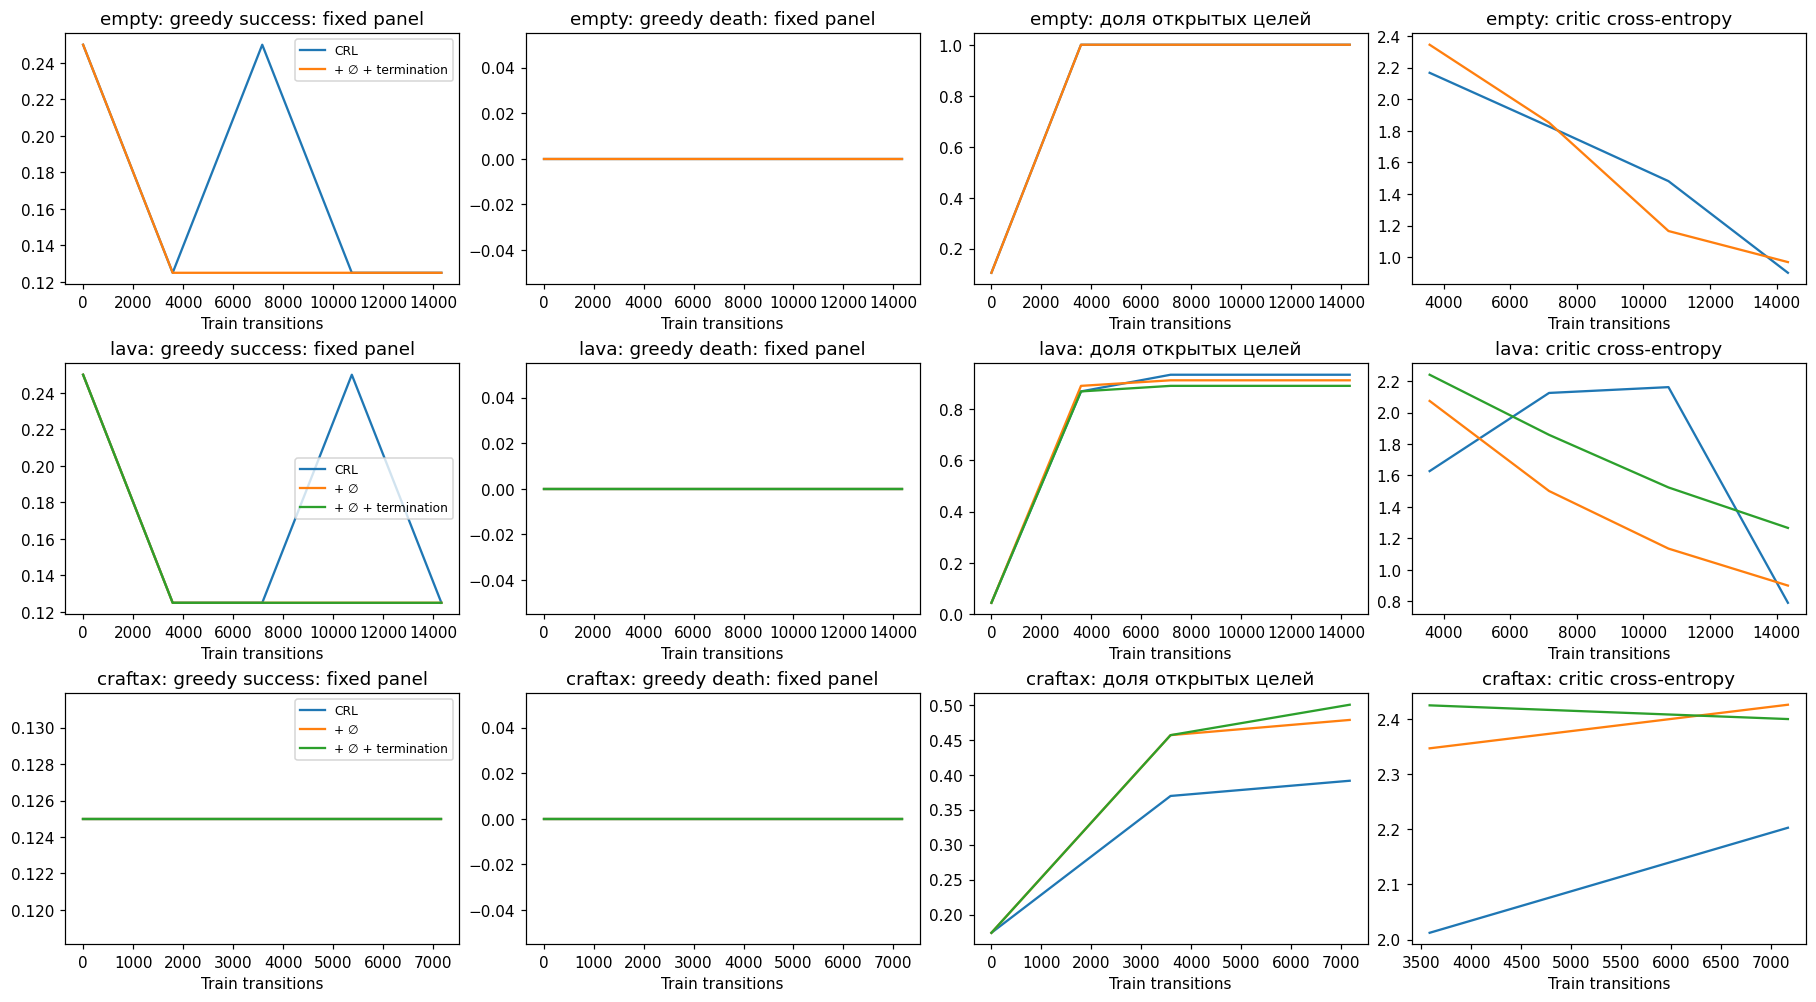

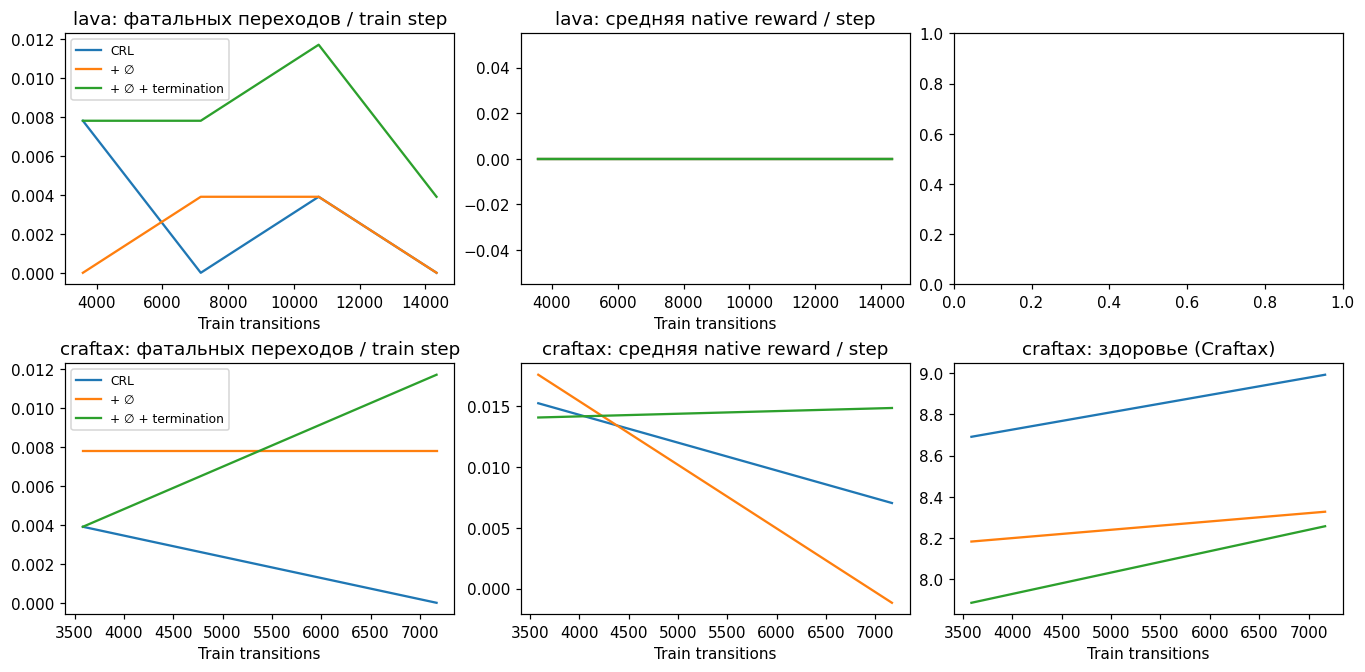

| Среда | Метод | Seeds | Все цели: success | Все цели: death | Время/run |
|:--|:--|--:|--:|--:|--:|
| empty | CRL | 1 | 0.16 | 0.00 | 17.9s |
| empty | + ∅ + termination | 1 | 0.11 | 0.00 | 10.7s |
| lava | CRL | 1 | 0.04 | 0.00 | 18.3s |
| lava | + ∅ | 1 | 0.04 | 0.00 | 14.4s |
| lava | + ∅ + termination | 1 | 0.07 | 0.00 | 14.3s |
| craftax | CRL | 1 | 0.09 | 0.04 | 23.3s |
| craftax | + ∅ | 1 | 0.09 | 0.02 | 9.9s |
| craftax | + ∅ + termination | 1 | 0.17 | 0.11 | 9.4s |

In [16]:
def plot_curves(collection, environments, metrics):
    fig, axes = plt.subplots(len(environments), len(metrics),
                             figsize=(4.1 * len(metrics), 3 * len(environments)),
                             squeeze=False, constrained_layout=True)
    for row, name in enumerate(environments):
        for (environment, label), runs in collection.items():
            if environment != name: continue
            x = np.mean([[h["steps"] for h in run.history] for run in runs], axis=0)
            for col, (key, title) in enumerate(metrics):
                values = np.array([[h[key] for h in run.history] for run in runs])
                if not np.isfinite(values).any(): continue
                mean, std = values.mean(0), values.std(0)
                axes[row, col].plot(x, mean, label=label)
                if len(runs) > 1:
                    axes[row, col].fill_between(x, mean-std, mean+std, alpha=.15)
                axes[row, col].set(xlabel="Train transitions", title=f"{name}: {title}")
        axes[row, 0].legend(fontsize=8)
    plt.show()

plot_curves(results, tuple(ENVIRONMENTS), [
    ("success", "greedy success: fixed panel"), ("death", "greedy death: fixed panel"),
    ("goals_seen", "доля открытых целей"), ("critic_loss", "critic cross-entropy")])
plot_curves(results, ("lava", "craftax"), [
    ("train_death", "фатальных переходов / train step"),
    ("native_reward", "средняя native reward / step"), ("health", "здоровье (Craftax)")])


def results_table(collection):
    lines = ["| Среда | Метод | Seeds | Все цели: success | Все цели: death | Время/run |",
             "|:--|:--|--:|--:|--:|--:|"]
    for (name, label), runs in collection.items():
        s = np.array([r.evaluation.success_rate for r in runs])
        d = np.array([r.evaluation.death_rate for r in runs])
        spread = lambda x: f"{x.mean():.2f}" if len(x)==1 else f"{x.mean():.2f} ± {x.std():.2f}"
        seconds = np.mean([r.elapsed_seconds for r in runs])
        lines.append(f"| {name} | {label} | {len(runs)} | {spread(s)} | {spread(d)} | {seconds:.1f}s |")
    display(Markdown(chr(10).join(lines)))

results_table(results)

### Успех по отдельным целям

Одна средняя метрика смешивает уже выполненные на старте цели, близкую навигацию и длинный крафт. Heatmap не скрывает этот эффект. Белые/жёлтые столбцы дальних ресурсов могут означать недостаток опыта, неверное ранжирование действий или недообучение. Посмотрите `goals_seen` и фактические посещения, прежде чем увеличивать сеть.

В Craftax «есть инструмент» и «рядом с верстаком» — разные predicates; proxy-цели stats проще не делают крафт решённым. Это конкретный учебный goal set, поэтому сравнивать проценты с цифрами для 136/512 целей из PDF нельзя.

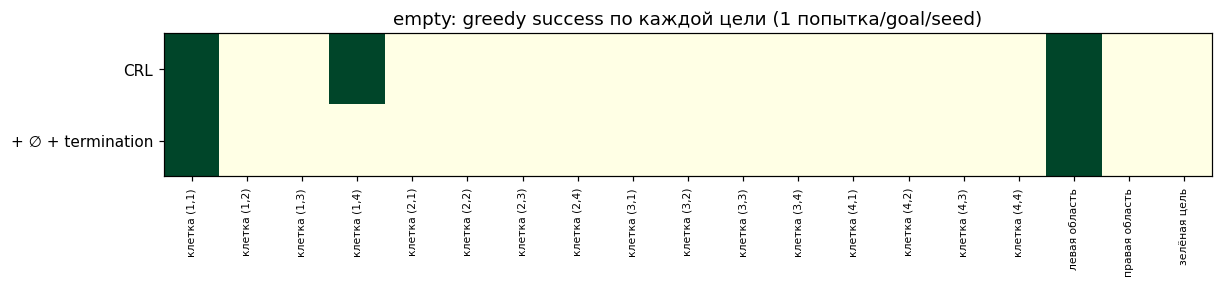

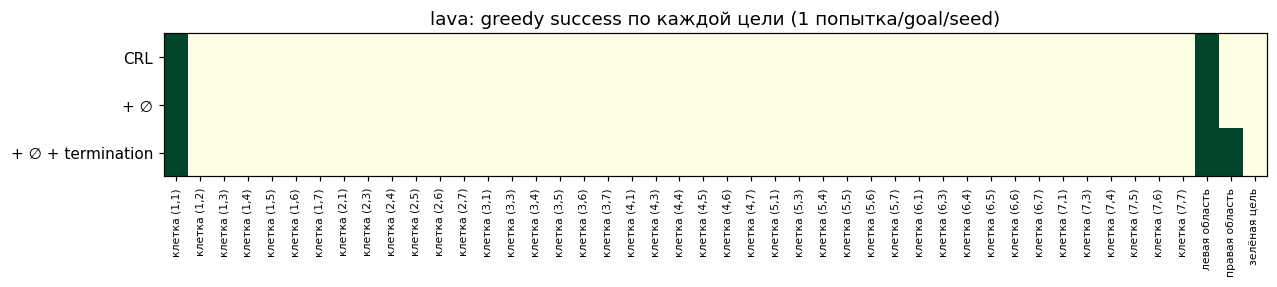

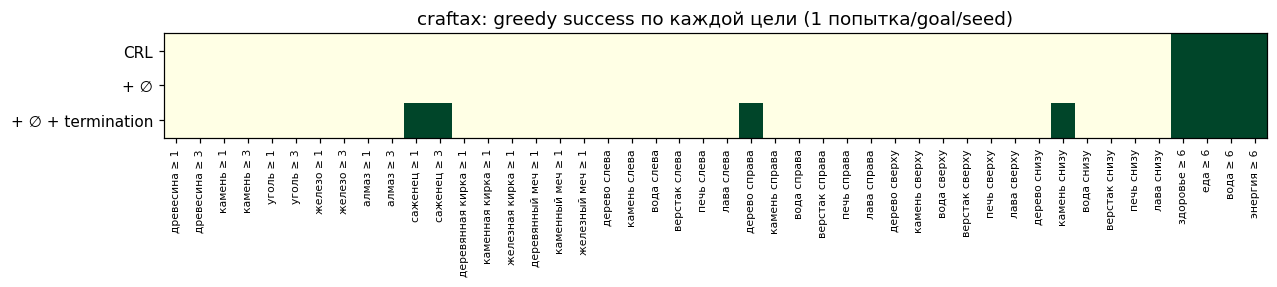

In [17]:
def plot_goals(collection, name):
    selected = [(label, runs) for (env_name, label), runs in collection.items() if env_name==name]
    first = selected[0][1][0]
    values = np.array([np.mean([r.evaluation.success for r in runs], axis=0) for _, runs in selected])
    fig, ax = plt.subplots(figsize=(max(11, first.goals.size*.25), 2.5), constrained_layout=True)
    ax.imshow(values, aspect="auto", cmap="YlGn", vmin=0, vmax=1)
    ax.set(yticks=range(len(selected)), yticklabels=[label for label, _ in selected],
           xticks=range(first.goals.size), xticklabels=first.goals.names,
           title=f"{name}: greedy success по каждой цели (1 попытка/goal/seed)")
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)
    plt.show()

for name in ENVIRONMENTS: plot_goals(results, name)

## 11. PPO baseline против Dual-CRL-PPO

Эти runs запускают полноценный on-policy PPO с GAE, shuffled minibatches и clipped policy loss. Teacher Dual не берётся из предыдущих CRL-абляций: **он начинается с нуля**. PPO и Dual имеют одинаковый config внутри одной среды. В Empty PPO-бюджет сокращён отдельно и не равен бюджету CRL-таблицы выше.

Полезно смотреть одновременно success, entropy, β, teacher CE, approximate KL и clip fraction. Слабый critic может учить плохим действиям; большая β способна ухудшить PPO. Низкая teacher CE показывает согласие со teacher, а не оптимальность teacher. β=0 в PPO делает показанную техническую CE неиспользуемой в objective — содержательно сравнивайте CE только у Dual.

empty    PPO             seed=0 | success=0.32 death=0.00 | 7.7s


empty    Dual-CRL-PPO    seed=0 | success=0.32 death=0.00 | 6.2s


craftax  PPO             seed=0 | success=0.13 death=0.09 | 10.3s


craftax  Dual-CRL-PPO    seed=0 | success=0.09 death=0.07 | 9.7s


| Среда | Метод | Seeds | Все цели: success | Все цели: death | Время/run |
|:--|:--|--:|--:|--:|--:|
| empty | PPO | 1 | 0.32 | 0.00 | 7.7s |
| empty | Dual-CRL-PPO | 1 | 0.32 | 0.00 | 6.2s |
| craftax | PPO | 1 | 0.13 | 0.09 | 10.3s |
| craftax | Dual-CRL-PPO | 1 | 0.09 | 0.07 | 9.7s |

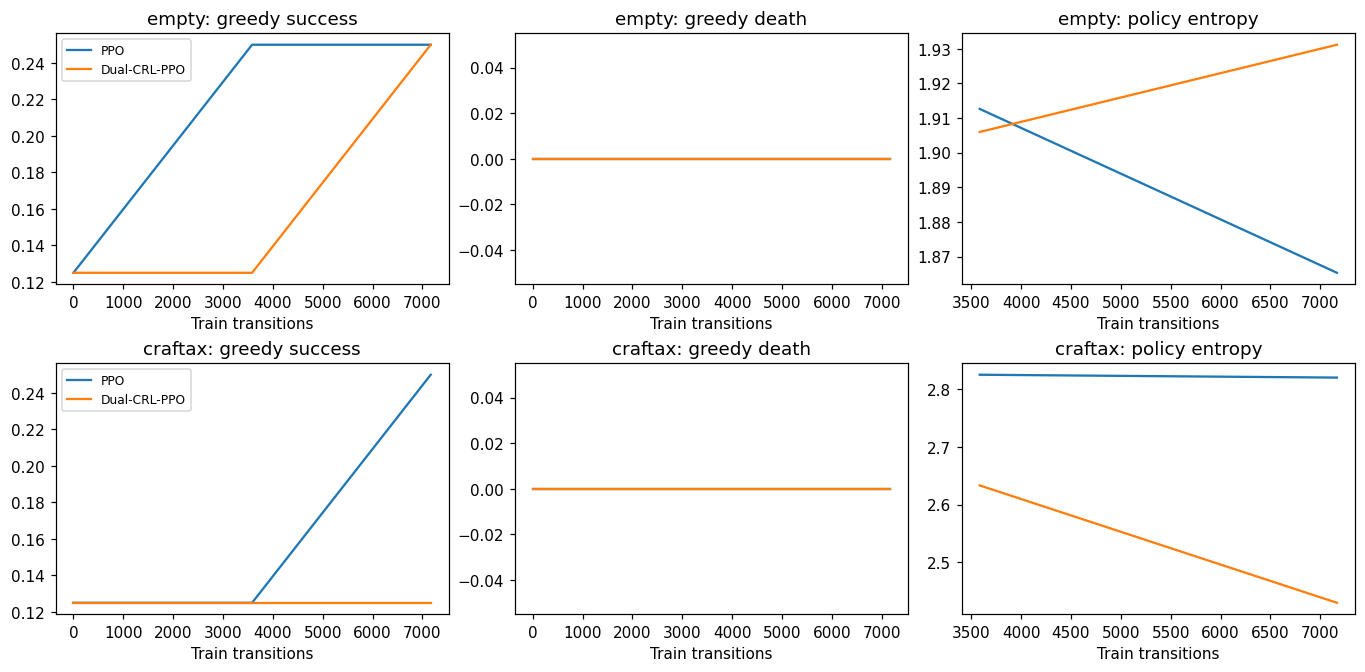

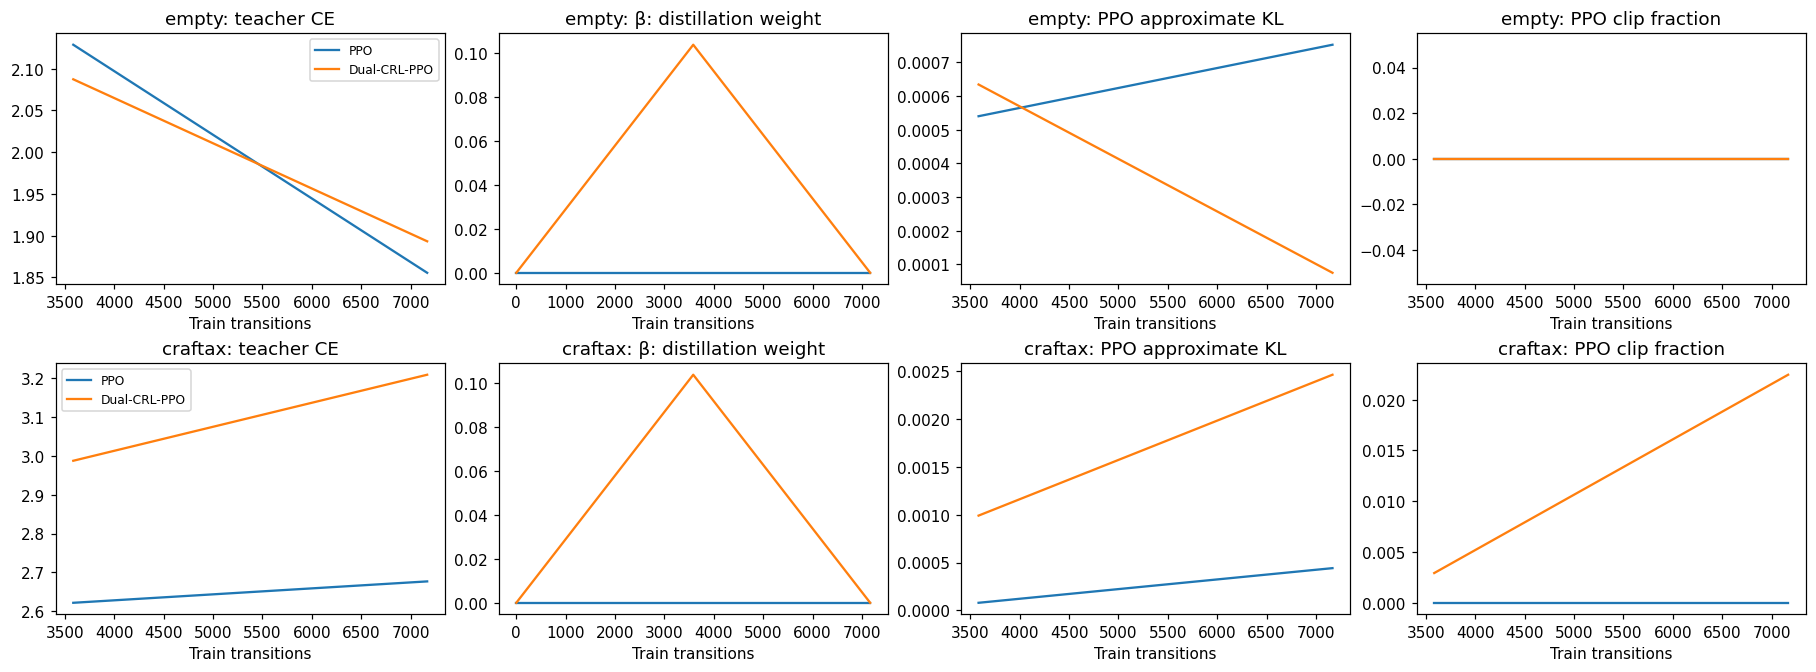

In [18]:
ppo_results = {}
if RUN_PPO:
    for name in ("empty", "craftax"):
        config = (replace(BASE, rounds=28, eval_every=14) if name=="empty" else CRAFTAX_CONFIG)
        for algorithm, label in (("ppo", "PPO"), ("dual", "Dual-CRL-PPO")):
            ppo_results[(name, label)] = []
            for seed in SEEDS:
                run = train(name, config, algorithm, seed, verbose=False)
                ppo_results[(name, label)].append(run)
                print(f"{name:8s} {label:15s} seed={seed} | success={run.evaluation.success_rate:.2f} "
                      f"death={run.evaluation.death_rate:.2f} | {run.elapsed_seconds:.1f}s", flush=True)
    results_table(ppo_results)
    plot_curves(ppo_results, ("empty", "craftax"), [
        ("success", "greedy success"), ("death", "greedy death"), ("entropy", "policy entropy")])
    plot_curves(ppo_results, ("empty", "craftax"), [
        ("bc_loss", "teacher CE"), ("beta", "β: distillation weight"),
        ("approx_kl", "PPO approximate KL"), ("clip_fraction", "PPO clip fraction")])
else:
    print("PPO не запускался: RUN_PPO=False. Это не результат проверки PPO.")

## 12. Инспектор критика: logits, probabilities и target mass

Выбирается **реальный сохранённый train anchor**, а не выдуманное состояние. Первое окно inspector показывает $f$, второе — categorical $p_g$ и residual $p_\varnothing$ для каждого действия. Некоторые цели могут иметь почти нулевую вероятность: увеличьте масштаб, смените цель или anchor, не делайте вывод по отсутствующему на линейной шкале столбику.

$p_\varnothing$ — **не вероятность умереть на следующем шаге**: сюда входит будущая дисконтированная масса поглощения и отсутствующих семантических целей. При `gamma_term != gamma` это ещё и модифицированный target. Scatter ниже рассчитан на последнем train rollout — это in-sample fit, **не независимая calibration-проверка**.

Политика статьи использует logit $f_g=\log(p_g/p_\varnothing)$, поэтому очень маленький $p_\varnothing$ иногда завышает предпочтение безопасного бездействия. Сравнение ranking по $f$ и по $p_g$ на одних весах отделяет это от качества самих меток. Контрольная eval ниже меняет только argmax и сохраняет RNG seeds.

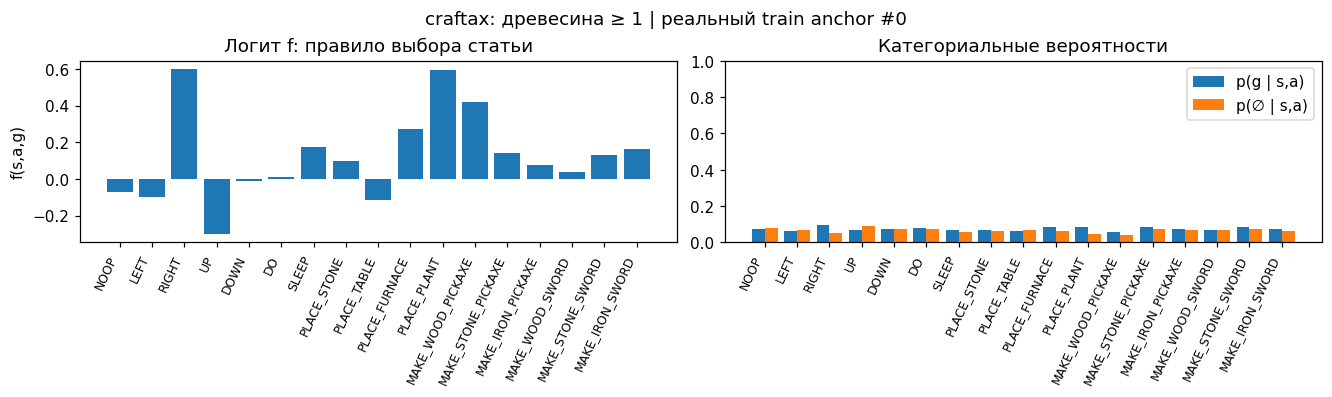

argmax f: RIGHT | argmax p(g): RIGHT


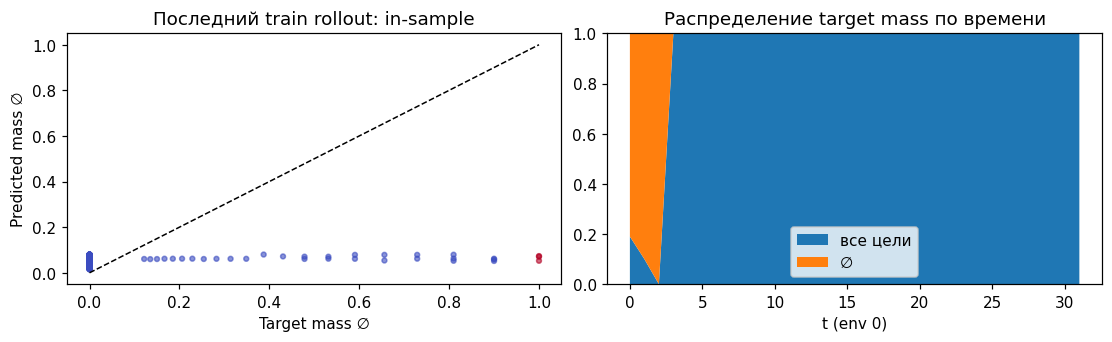

In [19]:
@jax.jit
def critic_predictions(critic, observations, descriptors, absorbing):
    logits = critic.apply_fn({"params": critic.params}, observations, descriptors)
    return logits, jnp.exp(class_log_probs(logits, absorbing))


def inspect_critic(run, goal=0, anchor=0):
    observations = run.probe.observation.reshape(-1, run.probe.observation.shape[-1])
    anchor = int(np.clip(anchor, 0, len(observations)-1))
    logits, probabilities = critic_predictions(run.critic, observations[anchor:anchor+1],
                                               run.goals.descriptors, run.config.absorbing)
    f, p = np.asarray(logits[0, :, goal]), np.asarray(probabilities[0])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
    x = np.arange(len(run.action_names))
    axes[0].bar(x, f); axes[0].set(title="Логит f: правило выбора статьи", ylabel="f(s,a,g)")
    axes[1].bar(x-.2, p[:, goal], .4, label="p(g | s,a)")
    axes[1].bar(x+.2, p[:, -1], .4, label="p(∅ | s,a)")
    axes[1].set(title="Категориальные вероятности", ylim=(0, 1)); axes[1].legend()
    for ax in axes:
        ax.set(xticks=x, xticklabels=run.action_names)
        plt.setp(ax.get_xticklabels(), rotation=65, ha="right", fontsize=8)
    fig.suptitle(f"{run.environment}: {run.goals.names[goal]} | реальный train anchor #{anchor}")
    plt.show()
    print("argmax f:", run.action_names[f.argmax()],
          "| argmax p(g):", run.action_names[p[:, goal].argmax()])


def inspect_targets(run):
    obs = run.probe.observation.reshape(-1, run.probe.observation.shape[-1])
    actions = np.asarray(run.probe.action).ravel()
    _, probs = critic_predictions(run.critic, obs, run.goals.descriptors, run.config.absorbing)
    predicted = np.asarray(probs)[np.arange(len(actions)), actions, -1]
    target = np.asarray(run.targets.distribution)[..., -1].ravel()
    fatal = np.asarray(run.probe.fatal).ravel()
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
    axes[0].scatter(target, predicted, c=fatal, cmap="coolwarm", s=10, alpha=.6)
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set(xlabel="Target mass ∅", ylabel="Predicted mass ∅", title="Последний train rollout: in-sample")
    y = np.asarray(run.targets.distribution[:, 0])
    axes[1].stackplot(range(len(y)), y[:, :-1].sum(-1), y[:, -1], labels=["все цели", "∅"])
    axes[1].set(xlabel="t (env 0)", ylim=(0, 1), title="Распределение target mass по времени")
    axes[1].legend(); plt.show()

probe_run = results[("craftax", "+ ∅ + termination")][0]
inspect_critic(probe_run, goal=probe_run.goals.find("древесина"), anchor=0)
inspect_targets(probe_run)

# Другая среда или точка:
# inspect_critic(results[("lava", "+ ∅ + termination")][0], goal=3, anchor=20)

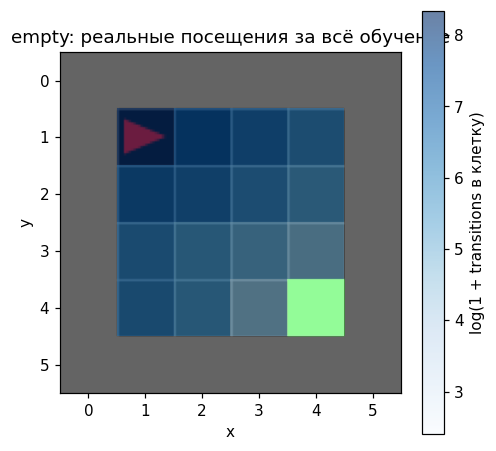

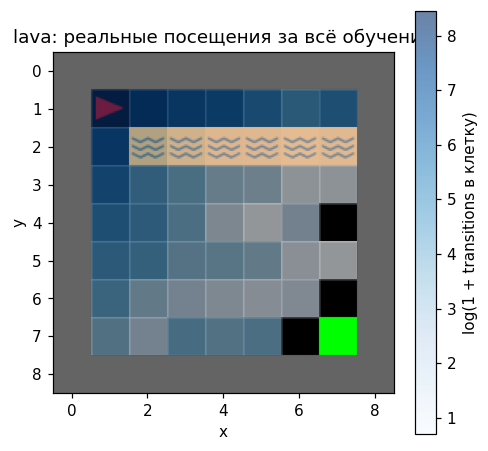

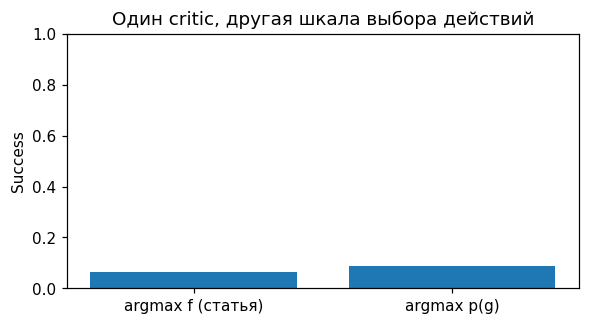

probability policy death: 0.0


In [20]:
def plot_visits(run):
    env = make_environment(run.environment, run.config, run.seed)
    if not isinstance(env, MiniGridBatch):
        env.close()
        raise ValueError("Для Craftax локальный render и глобальные координаты не совпадают.")
    visits = np.zeros((env.height, env.width))
    for x, y in run.visited_positions:
        if 0 <= x < env.width and 0 <= y < env.height:
            visits[y, x] += 1
    fig, ax = plt.subplots(figsize=(5, 5))
    extent = (-.5, env.width-.5, env.height-.5, -.5)
    ax.imshow(env.frame(), extent=extent)
    image = ax.imshow(np.ma.masked_where(visits==0, np.log1p(visits)), extent=extent,
                      cmap="Blues", alpha=.6)
    fig.colorbar(image, ax=ax, label="log(1 + transitions в клетку)")
    ax.set(title=f"{run.environment}: реальные посещения за всё обучение", xlabel="x", ylabel="y")
    plt.show(); env.close()

for name in ("empty", "lava"):
    plot_visits(results[(name, "+ ∅ + termination")][0])

# Те же веса, другой argmax: никаких дополнительных обучающих данных.
scoring_run = results[("lava", "+ ∅ + termination")][0]
probability_config = replace(scoring_run.config, action_score="probability")
probability_eval = evaluate("lava", probability_config, scoring_run.critic, scoring_run.actor,
                            "crl", np.arange(scoring_run.goals.size), seed=20_000)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["argmax f (статья)", "argmax p(g)"],
       [scoring_run.evaluation.success_rate, probability_eval.success_rate])
ax.set(ylim=(0, 1), ylabel="Success", title="Один critic, другая шкала выбора действий")
plt.show()
print("probability policy death:", probability_eval.death_rate)

## 13. Native рендеры и анимации политик

Кадры получаются renderer-ами **самих пакетов**, не нарисованными вручную картами. Все три анимации показывают обученные greedy политики на заранее выбранных целях, без отбора лучшего seed или успешного эпизода. Если агент зациклился, не нашёл древесину или погиб, это остаётся в результате.

Кадр при terminal сохраняется до reset. Снимки разрежены (`every=4`), чтобы notebook не стал огромным; управляющие шаги между ними всё равно исполняются. Native Craftax reward не является командуемой sparse reward PPO и не используется critic loss.

Для анимации другого метода: `policy_trace(ppo_results[("craftax","Dual-CRL-PPO")][0], goal=0)`. Статический просмотрщик может блокировать JS; выполните ячейку в доверенном Jupyter kernel для управления воспроизведением.

MiniGrid-Empty-6x6-v0 | цель встречалась: False | смерть: False | native steps: 64


MiniGrid-LavaCrossingS9N1-v0 | цель встречалась: False | смерть: False | native steps: 64


Craftax-Classic-Symbolic-v1 | цель встречалась: False | смерть: False | native steps: 64


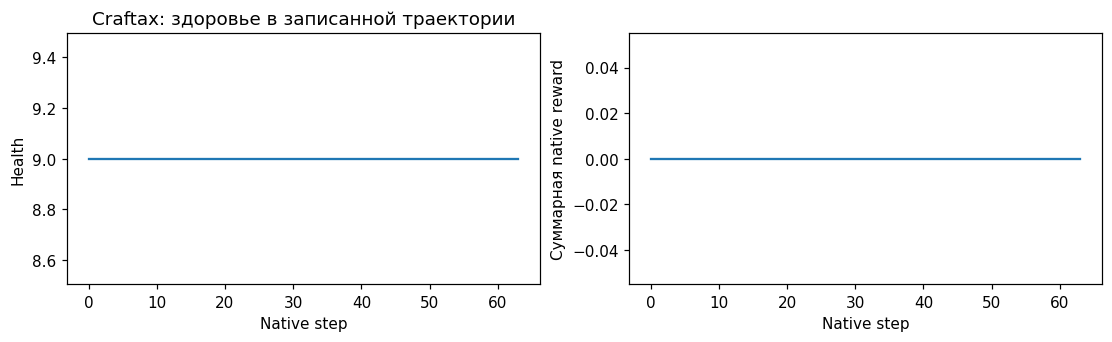

In [21]:
@dataclass
class Trace:
    frames: list[np.ndarray]
    health: list[float]
    rewards: list[float]
    achieved: list[bool]
    goal_name: str
    fatal: bool


def policy_trace(run, goal=0, steps=64, every=4, seed=30_000):
    env = make_environment(run.environment, run.config, seed)
    env.record_first = True
    frames, health, rewards, achieved = [env.frame()], [], [], []
    commands = jnp.full(env.batch_size, goal, jnp.int32)
    key = jax.random.PRNGKey(seed+1)
    died = False
    for t in range(steps):
        key, subkey = jax.random.split(key)
        if run.algorithm == "crl":
            action = critic_action(run.critic, env.observation, env.goals.descriptors,
                                   commands, subkey, 0., run.config.action_score=="probability", run.config.absorbing)
        else:
            action, _, _ = actor_action(run.actor, env.observation, env.goals.descriptors, commands, subkey, True)
        transition = env.step(action)
        health.append(float(transition.health[0])); rewards.append(float(transition.native_reward[0]))
        achieved.append(bool(transition.predicates[0, goal] and not transition.fatal[0]))
        done = bool(transition.terminated[0] | transition.truncated[0])
        if (t+1) % every == 0 or done:
            frames.append(env.last_frame)
        if done:
            died = bool(transition.fatal[0]); break
    env.close()
    return Trace(frames, health, rewards, achieved, run.goals.names[goal], died)


def animate_trace(trace, title):
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    image = ax.imshow(trace.frames[0]); ax.axis("off")
    ax.set_title(f"{title}\n{trace.goal_name}")
    def update(index):
        image.set_data(trace.frames[index])
        return [image]
    movie = animation.FuncAnimation(fig, update, frames=len(trace.frames), interval=220, blit=True)
    html = movie.to_jshtml(); plt.close(fig)
    print(title, "| цель встречалась:", any(trace.achieved), "| смерть:", trace.fatal,
          "| native steps:", len(trace.rewards))
    return HTML(html)

traces = {}
for name in ENVIRONMENTS:
    run = results[(name, "+ ∅ + termination")][0]
    goal = run.goals.find("древесина") if name=="craftax" else run.goals.find("зелёная")
    traces[name] = policy_trace(run, goal=goal)
    display(animate_trace(traces[name], ENVIRONMENTS[name]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
trace = traces["craftax"]
axes[0].plot(trace.health); axes[0].set(xlabel="Native step", ylabel="Health", title="Craftax: здоровье в записанной траектории")
axes[1].plot(np.cumsum(trace.rewards)); axes[1].set(xlabel="Native step", ylabel="Суммарная native reward")
plt.show()

## 14. Интерактивная лаборатория и свои runs

`target_lab` меняет формулу меток **без переобучения**: это быстрый способ понять параметр отдельно от SGD. `launch_widgets()` открывает те же ползунки и выбор anchor/goal критика. Большой inspector запускается кнопкой, чтобы не пересчитываться на каждом промежуточном движении ползунка.

`run_custom` создаёт независимые runs и возвращает состояния сетей. Изменяйте одну настройку за раз, сохраняйте seeds и бюджет. Для переключения среды не требуется менять код алгоритма: DoorKey уже зарегистрирован пакетом. Для продолжения существующего обучения понадобятся также состояния collector/env/replay/RNG, а не только веса — здесь `run_custom` начинает с нуля.

| Параметр | Что проверять | Что меняется |
|:--|:--|:--|
| `gamma=.8/.97/.995` | близкие и дальние цели | горизонт occupancy примерно $1/(1-\gamma)$ |
| `gamma_term=0/.5/.9/.97` | success и death вместе | дальность переноса terminal mass |
| `rao_blackwell=False` | разброс меток и seed | один случайный offset вместо усреднения |
| `k_max=4/16/64` | дальний крафт | усечение доступного будущего |
| `hidden`, `embedding_dim` | ошибки critic и цена | ёмкость encoders и ранг score matrix |
| `critic_updates`, `critic_lr` | CE и поведение | степень оптимизации на rollout |
| `replay_rollouts=1/4/16` | адаптация к policy | старые continuation policies |
| `epsilon_end=.05/.15/.5` | цели/посещения | исследование против эксплуатации |
| `action_score="probability"` | argmax f vs p | изменение policy, не target estimator |
| `bc_beta=0/.1/.2/1` | PPO vs teacher | насколько student доверяет critic |
| `entropy_coef`, `ppo_lr`, `ppo_epochs` | entropy/KL/clip fraction | исследование и размер PPO updates |
| `num_envs`, `rollout_len`, `rounds` | шаги и сходимость | бюджет, размер окна, compile/memory |
| `episode_limit` | длина попыток | time-limit native среды, не death penalty |
| `SEEDS` | устойчивость вывода | независимые инициализации и training RNG |

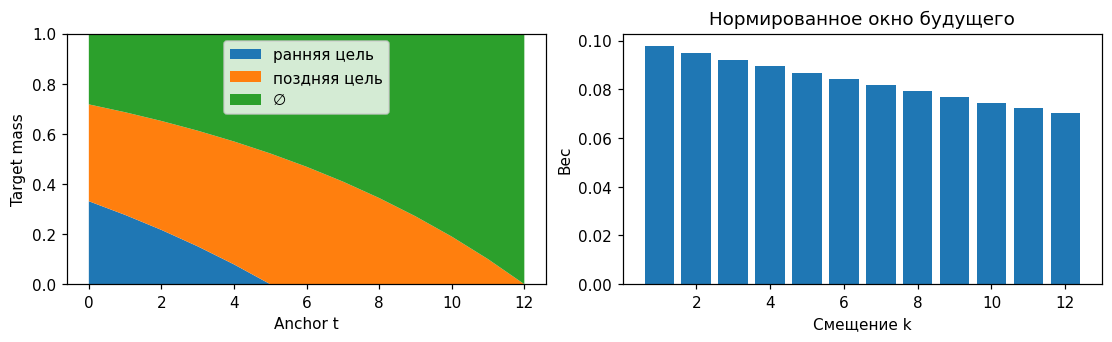

In [22]:
def target_lab(gamma=.97, gamma_term=.9, k_max=12):
    # Две ранние/поздние цели, 12 живых наблюдений, затем смерть.
    predicates = jnp.array([[1., 0.]] * 5 + [[0., 1.]] * 7 + [[0., 0.]])[:, None]
    term = jnp.arange(13)[:, None] == 12
    options = TargetOptions(gamma, gamma_term, k_max, True, True)
    targets = build_targets(predicates, term, jnp.zeros_like(term), term,
                            jax.random.PRNGKey(0), options)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
    axes[0].stackplot(range(13), np.asarray(targets.distribution[:, 0]).T,
                     labels=["ранняя цель", "поздняя цель", "∅"])
    axes[0].set(ylim=(0, 1), xlabel="Anchor t", ylabel="Target mass"); axes[0].legend()
    weights = gamma ** np.arange(k_max); weights /= weights.sum()
    axes[1].bar(np.arange(1, k_max+1), weights)
    axes[1].set(xlabel="Смещение k", ylabel="Вес", title="Нормированное окно будущего")
    plt.show()


def launch_widgets(run=None):
    import ipywidgets as widgets
    run = probe_run if run is None else run
    # manual=True: большой inspector не вычисляется при каждом сдвиге ползунка.
    display(widgets.interactive(target_lab,
        gamma=widgets.FloatSlider(value=.97, min=.5, max=.995, step=.005, continuous_update=False),
        gamma_term=widgets.FloatSlider(value=.9, min=0, max=.995, step=.005, continuous_update=False),
        k_max=widgets.IntSlider(value=12, min=1, max=12, continuous_update=False)))
    count = run.config.rollout_len * run.config.num_envs
    def show(goal, anchor):
        inspect_critic(run, goal, anchor)
    display(widgets.interactive(show, {"manual": True},
        goal=widgets.Dropdown(options=[(name, i) for i, name in enumerate(run.goals.names)], value=0),
        anchor=widgets.IntSlider(min=0, max=count-1, value=0, continuous_update=False)))


def run_custom(environment="lava", algorithm="crl", seeds=(0,), **changes):
    base = CRAFTAX_CONFIG if environment=="craftax" else BASE
    config = replace(base, **changes).validate()
    custom = [train(environment, config, algorithm, seed) for seed in seeds]
    collection = {(environment, f"custom {algorithm}"): custom}
    results_table(collection)
    plot_curves(collection, (environment,), [("success", "success"), ("death", "death"), ("goals_seen", "открытые цели")])
    return custom


target_lab()
# В активном Jupyter откройте ползунки:
# launch_widgets()
# Собственные эксперименты (по очереди, меняйте одну настройку):
# sampled = run_custom(rao_blackwell=False)
# shorter_penalty = run_custom(gamma_term=.5)
# probability = run_custom(action_score="probability")
# doorkey = run_custom(environment="MiniGrid-DoorKey-6x6-v0", rounds=100)
# dual = run_custom(environment="craftax", algorithm="dual", bc_beta=.1, rounds=200)

## 15. Масштабирование целей и новые предикаты

Параметры общей $\phi$ и goal encoder $\psi$ не зависят от числа описаний $G$ при фиксированной размерности observation/descriptor. Однако **compute и память не становятся константными**: descriptors занимают $O(GD_g)$, logits — $O(BAG)$, full-softmax loss и target-применение растут с G. При observation-level goals наши dense masks могут быть дорогими; разреженное кодирование — отдельная оптимизация.

График — аналитический подсчёт параметров: факторизация против общей MLP с независимыми per-goal outputs. Это не измерение FLOPs или walltime. Ниже также проверяется настоящий forward на всех активируемых symbolic features Craftax. Число features берётся из установленной версии пакета, а не копируется из PDF. Мы не фильтруем невозможные признаки и не переобучаем на этом расширенном наборе, поэтому это **проверка интерфейса масштабирования**, не результат обучения тысячам новых целей.

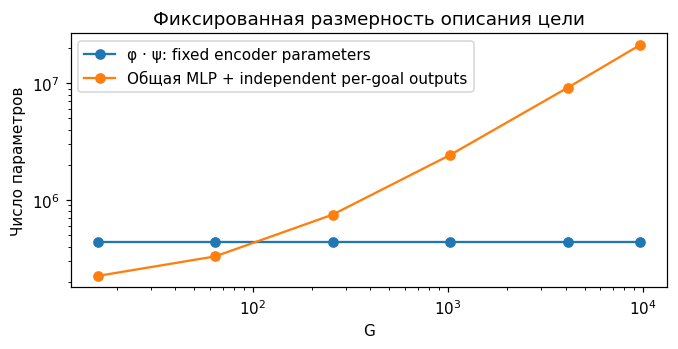

Параметров CRL: 435520 | obs_dim: 1345 | G: 46


Forward pass на observation-level goals: (1, 17, 1345) (эти новые цели НЕ обучались и их качество не проверено)


In [23]:
# Меряем фактическую структуру параметров; это НЕ бенчмарк FLOPs Craftax из статьи.
run = probe_run
goal_counts = np.array([16, 64, 256, 1024, 4096, 9637])
critic_parameters = sum(leaf.size for leaf in jax.tree.leaves(run.critic.params))
obs_dim = run.probe.observation.shape[-1]
actions = len(run.action_names)
# Независимые per-goal outputs той же общей MLP: базовая сеть + Dense(hidden, A*G).
trunk = (obs_dim+1)*run.config.hidden + (run.config.hidden+1)*run.config.hidden
independent = trunk + (run.config.hidden+1)*actions*goal_counts
fig, ax = plt.subplots(figsize=(7, 3))
ax.loglog(goal_counts, np.full_like(goal_counts, critic_parameters), "o-", label="φ · ψ: fixed encoder parameters")
ax.loglog(goal_counts, independent, "o-", label="Общая MLP + independent per-goal outputs")
ax.set(xlabel="G", ylabel="Число параметров", title="Фиксированная размерность описания цели")
ax.legend(); plt.show()
print("Параметров CRL:", critic_parameters, "| obs_dim:", obs_dim, "| G:", run.goals.size)

# Пакетные symbolic features могут стать новым большим goal set без изменения physics.
env = make_environment("craftax", CRAFTAX_CONFIG)
observation_goals = craftax_goal_space(env.obs_dim, kind="observation")
large_logits = run.critic.apply_fn({"params": run.critic.params}, env.observation[:1], observation_goals.descriptors)
assert large_logits.shape == (1, env.n_actions, observation_goals.size)
print("Forward pass на observation-level goals:", large_logits.shape,
      "(эти новые цели НЕ обучались и их качество не проверено)")
env.close()

## 16. Как читать JAX-код, если вы привыкли к PyTorch

| Здесь | Примерный PyTorch-аналог | Существенное отличие |
|:--|:--|:--|
| Flax `Module.init(key, x)` | создание `nn.Module` + init | параметры возвращаются явно |
| `module.apply({"params": p}, x)` | `module(x)` | нет скрытого текущего p |
| `jax.value_and_grad(loss_fn)(p)` | loss + `loss.backward()` | gradient — возвращённый PyTree |
| `state.apply_gradients(grads=g)` | `optimizer.step()` | возвращается **новый** TrainState |
| `jax.lax.stop_gradient(x)` | `x.detach()` | разрывает зависимость для AD |
| `jax.nn.log_softmax` | `F.log_softmax` | лог-форма для численной устойчивости |
| `jax.random.categorical(key, logits)` | `Categorical(logits=...).sample()` | key явный и одноразовый |
| `jax.random.split(key)` | отдельные `Generator`/seed | не повторяйте один key без намерения |
| `jax.vmap(function)` | batch-код / `torch.func.vmap` | векторизация pure function |
| `jax.lax.scan` | цикл с накоплением состояния | компилируемый цикл, immutable carry |
| `jax.jit` | ближе к `torch.compile` | shapes/static metadata задают специализацию |
| `jnp.einsum` | `torch.einsum` | те же обозначения осей |
| `lax.dynamic_update_slice` | запись в часть buffer | возвращает новый массив, без in-place API |

**Не делайте `np.asarray` внутри jitted loss/update:** host conversion ломает tracing. В notebook NumPy используется на границе Python MiniGrid, при логировании, проверках и рисовании. Не передавайте изменяемую Python-среду внутрь JIT. Не пытайтесь менять размер массива на основании traced boolean: маски нужны именно для сохранения статических форм.

### Вопросы для глубокого понимания

**Почему не BCE по каждой цели?** Это было бы другое определение target/value. В статье масса состояния делится между co-satisfied goals, и categorical CE оценивает именно Eq. 5. Независимые цели могут быть полезны, но это уже иной метод.

**Почему не обычный штраф −1 за смерть?** Critic CRL не использует reward; он классифицирует будущее. Residual class делает прекращённое будущее общей отрицательной информацией для всех целей, не вводя отдельный reward scale.

**Почему RB не гарантирует лучший агент?** Он уменьшает условную дисперсию метки, но остаются exploration, finite-window bias, approximation error и изменяющееся распределение поведения. Низкий loss не обеспечивает полезный action ranking.

**Можно ли назвать p(∅) confidence или death probability?** Без дополнительных условий — нет. Это residual semantic occupancy mass для конкретного target definition. Пустые predicates тоже попадают туда.

**Почему может ухудшиться success при улучшении survival?** Безопасное стояние сохраняет жизнь, но не открывает крафт. Командуемая first-hit success, нормированная occupancy critic и density-ratio logits оптимизируют разные величины. Поэтому есть и графики success/death, и посещения, и альтернативное ranking.

**Чему учится PPO?** Завершать текущую команду с sparse reward, с помощью собственного value/GAE и необязательной teacher CE. Это не behavioral cloning, замаскированный названием PPO. Critic PPO-baseline не обучается.

**Куда смотреть при плохом результате?** Сначала API flags/targets и native frames, затем coverage/достижимость, затем critic CE и action scores, потом PPO entropy/KL/β. Не лечите отсутствие данных одной шириной сети.

**Что нужно для серьёзного Craftax reproduction?** Точные goals/scheduler/архитектура статьи, больше параллельных envs, JAX scan collector, большой бюджет, несколько seeds, повторные held-out evaluations и отдельное измерение FLOPs. Этот notebook делает проверяемый механизм и лабораторию, не заменяет такой проект.

### Соответствие статье

| Механизм | Реализация |
|:--|:--|
| Eq. 3–5: semantic predicates, split mass, categorical CE | `GoalSpace`, `semantic_labels`, `fit_critic` |
| Eq. 6: RB future-offset expectation | `build_targets` |
| Eq. 7: фиксированный logit ∅ = 0 | `class_log_probs` |
| Eq. 8: terminal-discounted targets | `TargetOptions`, episode/future masks |
| Eq. 9: annealed BC + PPO | `teacher_actions`, `fit_ppo`, `train(...,"dual")` |
| Native experimental environments | pip `craftax` и `minigrid`; никаких самописных MDP |
| Большая CNN, точные Craftax goals, $10^9$ steps | не воспроизводятся этим CPU-профилем |

Источник формул — предоставленный PDF, §2–3 и Appendix B. Команды/обращения к рецензентам в документе не являются инструкциями для notebook.

In [24]:
verify_targets()
all_runs = [run for runs in {**results, **ppo_results}.values() for run in runs]
for run in all_runs:
    assert np.isfinite(run.evaluation.success_rate)
    assert run.evaluation.goal_ids.size == run.goals.size
    assert len(run.history) >= 2
    assert run.visited_positions.shape[0] == run.config.rounds * run.config.rollout_len * run.config.num_envs
    assert all(np.isfinite(np.asarray(leaf)).all() for leaf in jax.tree.leaves((run.critic.params, run.actor.params)))
print("Завершено runs:", len(all_runs), "| learning seeds:", SEEDS)
print("Train transitions:", sum(run.config.rounds*run.config.rollout_len*run.config.num_envs for run in all_runs))
print("Критики обучались:", sum(run.algorithm != "ppo" for run in all_runs))
print("PPO-политики обучались:", sum(run.algorithm != "crl" for run in all_runs))
print("PPO:", "выполнен" if RUN_PPO else "пропущен настройкой")
print("Результаты относятся к этим pip-версиям, seed и учебному бюджету. Сходимость Craftax не заявляется.")

Targets: нормировка, индексы, fatal/success/time-limit, reset и пустые предикаты — OK.
Завершено runs: 12 | learning seeds: (0,)
Train transitions: 121856
Критики обучались: 10
PPO-политики обучались: 4
PPO: выполнен
Результаты относятся к этим pip-версиям, seed и учебному бюджету. Сходимость Craftax не заявляется.
